# Análise Exploratória de Dados (EDA) - Série Histórica de Preços do Trigo

Este notebook realiza a Análise Exploratória de Dados e o diagnóstico estatístico da série diária de preços do trigo, seguindo a mesma estrutura metodológica adotada para o arroz (`analise_exploratoria.ipynb`). O objetivo é caracterizar o comportamento da série e reunir as evidências estatísticas que fundamentam a especificação dos modelos preditivos (SARIMA, SARIMAX e LSTM).

**Fonte dos dados:** Preço médio do Trigo CEPEA/ESALQ - **Rio Grande do Sul**, preço à vista em Reais por tonelada (R$/t), extraído da planilha `Serie de precos trigo media RS.xls` e tratado pelo script `src/data/limpeza_trigo.py` (calendário diário contínuo com *forward fill* nos finais de semana e feriados). Por ser uma série gaúcha, ela é geograficamente coerente com as variáveis climáticas do dataset final, obtidas de estações do Rio Grande do Sul (Cruz Alta, Passo Fundo e Santa Rosa).

**Roteiro da análise:**
1. Introdução e Carregamento dos Dados
2. Análise Descritiva e Visualização da Série Temporal
3. Análise de Estacionariedade (ADF e KPSS)
4. Decomposição da Série Temporal
5. Análise de Autocorrelação (ACF e PACF)
6. Conclusões e Implicações para a Modelagem

### Validação do Ambiente de Execução
Este bloco realiza uma checagem do interpretador ativo para garantir que o Jupyter Notebook está utilizando o ambiente correto e mapeando adequadamente os caminhos das bibliotecas.

In [1]:
import sys

print("Caminho do Python atual:", sys.executable)
print("\nVersão do Python:", sys.version)
print("\nLista de caminhos de busca (sys.path):")
for path in sys.path:
  print("-", path)

Caminho do Python atual: C:\Users\Bruno Origem Noronha\AppData\Local\Programs\Python\Python313\python.exe

Versão do Python: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]

Lista de caminhos de busca (sys.path):
- C:\Users\Bruno Origem Noronha\AppData\Local\Programs\Python\Python313\python313.zip
- C:\Users\Bruno Origem Noronha\AppData\Local\Programs\Python\Python313\DLLs
- C:\Users\Bruno Origem Noronha\AppData\Local\Programs\Python\Python313\Lib
- C:\Users\Bruno Origem Noronha\AppData\Local\Programs\Python\Python313
- 
- C:\Users\Bruno Origem Noronha\AppData\Roaming\Python\Python313\site-packages
- C:\Users\Bruno Origem Noronha\AppData\Local\Programs\Python\Python313\Lib\site-packages


### Gerenciamento Robusto de Dependências
Este bloco realiza a instalação programática das bibliotecas essenciais (`pandas`, `numpy`, `matplotlib`, `seaborn` e `statsmodels`) de forma segura, utilizando o módulo `subprocess` em conjunto com o caminho absoluto do interpretador Python ativo (`sys.executable`).

**Justificativa Técnica:**
Diferente do comando de terminal tradicional (`!pip`), esta abordagem via script evita falhas de interpretação de shell causadas por espaços ou caracteres especiais nos diretórios do sistema operacional (como nomes de usuário no Windows), garantindo que os pacotes sejam injetados com precisão no kernel correto do projeto. Em relação ao notebook do arroz, acrescentam-se `seaborn` (visualização de distribuições) e `statsmodels` (testes de estacionariedade, decomposição e funções de autocorrelação).

In [2]:
import subprocess
import sys

# Instalação limpa utilizando o executável de forma segura para caminhos com espaços
subprocess.check_call(
    [sys.executable, "-m", "pip", "install", "-q", "pandas", "numpy", "matplotlib", "seaborn", "statsmodels"]
)
print("Bibliotecas instaladas com sucesso!")

Bibliotecas instaladas com sucesso!


### Inicialização do Ambiente e Identidade Visual Padrão
Este bloco realiza a importação das bibliotecas fundamentais para computação científica, manipulação de dados e econometria de séries temporais, e define a identidade visual global para todas as figuras da monografia.

**Justificativa Técnica:**
O uso do dicionário `plt.rcParams.update()` padroniza elementos estéticos essenciais — como a família tipográfica limpa (`sans-serif`), a espessura sutil das bordas dos eixos e a resolução de alta definição (`figure.dpi = 300`) —, garantindo consistência visual com as figuras do arroz e um padrão gráfico estritamente profissional para exportação direta para o documento final. A paleta de cores (`ACCENT`, `ACCENT_SEC`, `LIGHT`) é exatamente a mesma do notebook do arroz.

In [3]:
# Importações fundamentais para manipulação de dados e gráficos
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ferramentas econométricas de séries temporais
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss

# O KPSS emite um aviso quando a estatística fica fora da tabela de valores críticos
# (o p-value real é menor que 0,01 ou maior que 0,10). O aviso é tratado no texto.
warnings.filterwarnings("ignore", category=InterpolationWarning)
# Avisos de mudança futura de API do statsmodels (não afetam os resultados)
warnings.filterwarnings("ignore", category=FutureWarning)

# Configuração de identidade visual padrão para a monografia (mesma do arroz)
LIGHT = "#f8f9fa"
ACCENT = "#2c3e50"  # Cor principal para as séries
ACCENT_SEC = "#e67e22"  # Cor de destaque

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.edgecolor": "#cccccc",
    "axes.linewidth": 0.8,
    "figure.dpi": 300,  # Garante alta resolução ao exportar as figuras
})

MESES_NOMES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

print("Ambiente inicializado com sucesso!")

Ambiente inicializado com sucesso!


## 1. Introdução e Carregamento dos Dados

### Carregamento e Inspeção Inicial da Base de Dados
Este bloco realiza a importação do dataset tratado de preços do trigo a partir do diretório processado do projeto e executa uma auditoria estrutural inicial dos dados.

**Justificativa Técnica:**
O uso de `os.path.join()` assegura a portabilidade dos caminhos de diretório entre diferentes sistemas operacionais (como Windows e Linux). Diferentemente do notebook do arroz, a coluna `data` já é convertida para `datetime` e definida como **índice temporal** no próprio carregamento (`parse_dates` e `index_col`). Um `DatetimeIndex` habilita nativamente as operações de séries temporais do `pandas` e do `statsmodels` (reamostragem, decomposição, defasagens), além de garantir a ordenação cronológica.

In [4]:
# Caminho relativo para o dataset processado de trigo
caminho_dados = os.path.join("..", "data", "processed", "preco_trigo_limpo.csv")

# Carregando o DataFrame com a data como índice temporal
df_trigo = pd.read_csv(caminho_dados, parse_dates=["data"], index_col="data")

# Ordenando cronologicamente por garantia
df_trigo = df_trigo.sort_index()

# Exibindo as 5 primeiras linhas para conferir as colunas (preço em BRL e USD)
display(df_trigo.head())

# Exibindo informações gerais (tipos de dados, índice e valores nulos)
df_trigo.info()

,preco_brl,preco_usd
data,,
2008-01-02,454.62,256.56
2008-01-03,457.22,260.97
2008-01-04,457.22,260.52
2008-01-05,457.22,260.52
2008-01-06,457.22,260.52


<class 'pandas.DataFrame'>
DatetimeIndex: 6684 entries, 2008-01-02 to 2026-04-20
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   preco_brl  6684 non-null   float64
 1   preco_usd  6684 non-null   float64
dtypes: float64(2)
memory usage: 156.7 KB


### Verificação de Integridade da Série Temporal
Antes de qualquer análise estatística, é necessário auditar se o tratamento aplicado na etapa de limpeza produziu uma série **contínua, completa e sem lacunas**.

**Justificativa Técnica:**
Os modelos da família ARIMA e as redes LSTM pressupõem observações igualmente espaçadas no tempo. Por isso, verificam-se três pontos: (i) a ausência de valores nulos; (ii) a regularidade do calendário — todo intervalo entre duas datas consecutivas deve ser de exatamente 1 dia; e (iii) a proporção de dias que foram preenchidos por *forward fill* (finais de semana e feriados, em que o mercado físico não negocia e o preço repete a última cotação útil).

In [5]:
serie = df_trigo["preco_brl"]

# 1. Dimensões e período coberto
print(f"Dimensões do DataFrame: {df_trigo.shape[0]} linhas x {df_trigo.shape[1]} colunas")
print(f"Período coberto: {serie.index.min():%d/%m/%Y} a {serie.index.max():%d/%m/%Y}")
print(f"Extensão: {(serie.index.max() - serie.index.min()).days / 365.25:.1f} anos")

# 2. Valores nulos por coluna
print("\nValores nulos por coluna:")
print(df_trigo.isna().sum().to_string())

# 3. Regularidade do calendário (todas as diferenças entre datas devem ser de 1 dia)
intervalos = serie.index.to_series().diff().dropna().dt.days.value_counts()
print("\nIntervalos entre datas consecutivas (dias: ocorrências):")
print(intervalos.to_string())
print(f"Frequência inferida pelo pandas: {pd.infer_freq(serie.index)}")

# 4. Dias sem variação de preço (efeito do forward fill em fins de semana e feriados)
dias_sem_variacao = (serie.diff() == 0).sum()
fins_de_semana = (serie.index.dayofweek >= 5).sum()
print(f"\nDias sem variação em relação ao dia anterior: {dias_sem_variacao} "
      f"({dias_sem_variacao / len(serie):.1%} da série)")
print(f"Dias de fim de semana no calendário: {fins_de_semana} ({fins_de_semana / len(serie):.1%})")

Dimensões do DataFrame: 6684 linhas x 2 colunas
Período coberto: 02/01/2008 a 20/04/2026
Extensão: 18.3 anos

Valores nulos por coluna:
preco_brl    0
preco_usd    0

Intervalos entre datas consecutivas (dias: ocorrências):
data
1    6683
Frequência inferida pelo pandas: D

Dias sem variação em relação ao dia anterior: 2341 (35.0% da série)
Dias de fim de semana no calendário: 1910 (28.6%)


A auditoria confirma que a série está pronta para a análise estatística:

* **Completude:** não há valores nulos em nenhuma das colunas, o que comprova a eficácia do tratamento de finais de semana e feriados realizado na etapa de limpeza.
* **Calendário contínuo:** todas as datas consecutivas distam exatamente 1 dia (frequência diária `D`), condição necessária para a aplicação dos modelos SARIMA e para a construção das janelas deslizantes da LSTM.
* **Período:** a série tratada vai de 02/01/2008 (primeira cotação do ano, pois 01/01 é feriado) a 20/04/2026. No dataset final integrado (`dataset_final_trigo.csv`), o início desloca-se para **fevereiro de 2008**, pois as primeiras 30 observações são consumidas pela criação das defasagens e médias móveis de 30 dias.
* **Efeito do *forward fill*:** cerca de 35% dos dias não apresentam variação de preço, proporção compatível com os finais de semana (≈ 28,6% do calendário) somados aos feriados e a dias úteis em que a cotação não se alterou. Esse padrão semanal de "repetição" deixa uma assinatura de periodicidade 7 na série diferenciada, que será revisitada na análise de autocorrelação (Seção 5).

## 2. Análise Descritiva e Visualização da Série Temporal

### Visualização da Série Histórica (BRL)
Este bloco gera a visualização gráfica oficial da série histórica de preços do trigo, no mesmo padrão adotado para o arroz.

**Justificativa Técnica:**
Utiliza-se a biblioteca `matplotlib` configurada com a identidade visual da monografia para plotar a evolução dos preços em Reais (BRL) entre 2008 e 2026. A anotação do máximo e do mínimo históricos auxilia a leitura dos choques de preço discutidos a seguir. A adição de grade pontilhada, legendas customizadas e o método `plt.tight_layout()` garantem o rigor estético e a legibilidade exigidos em trabalhos acadêmicos.

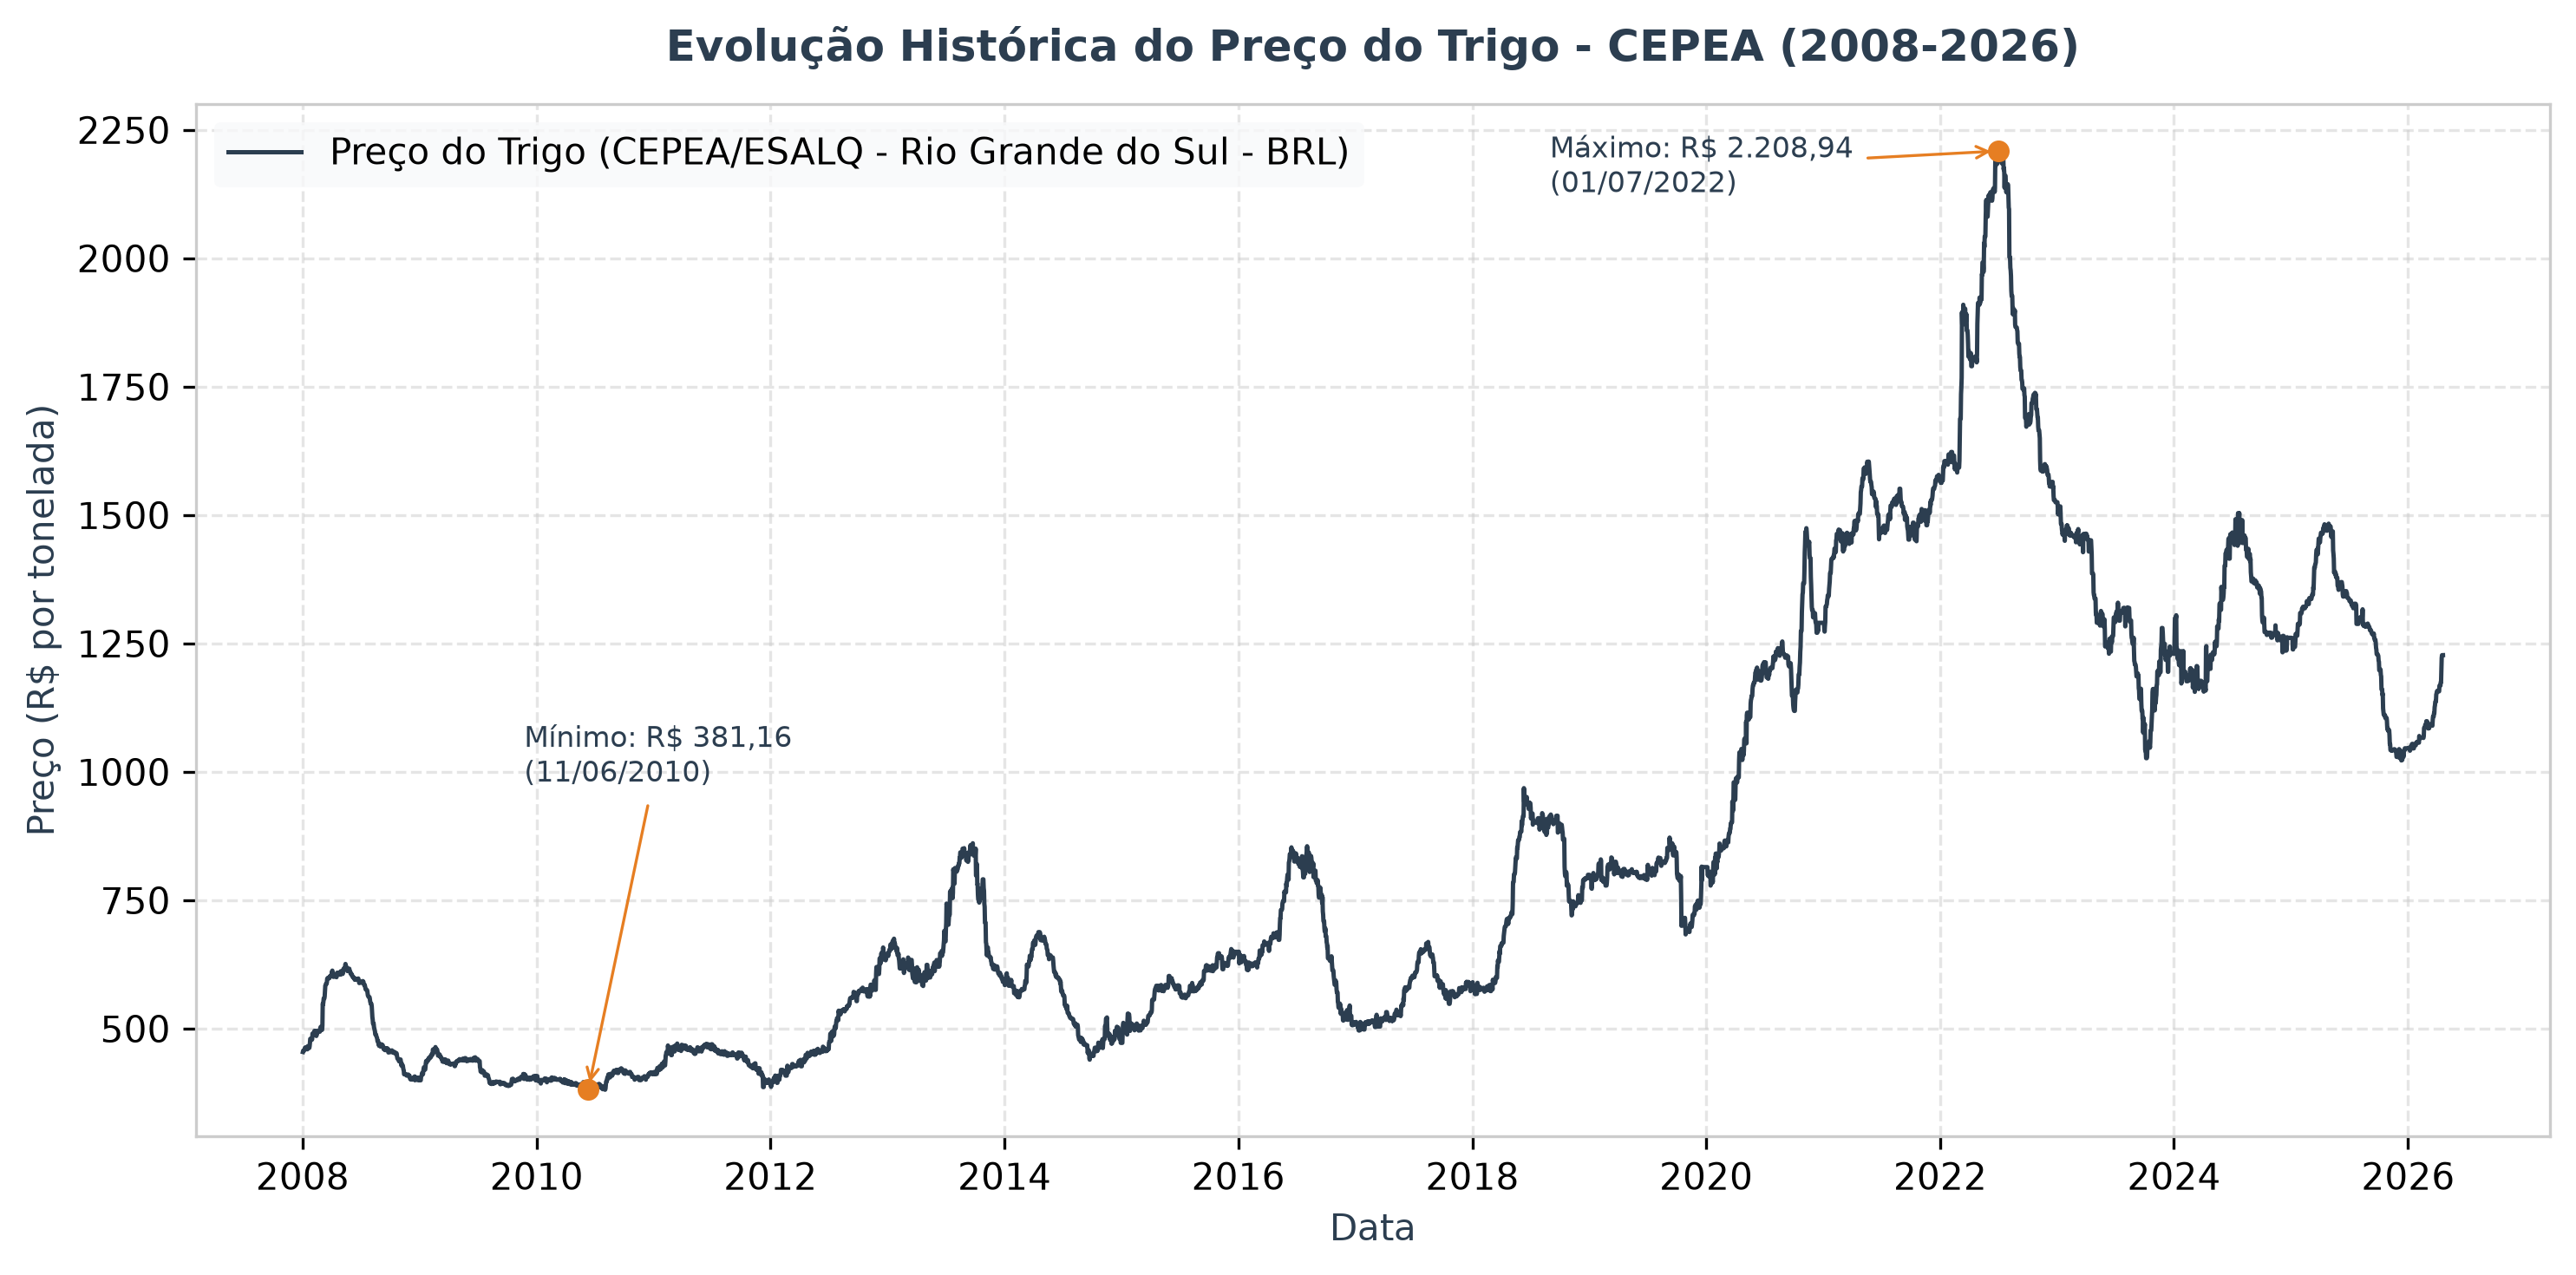

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    serie.index,
    serie,
    color=ACCENT,
    linewidth=1.2,
    label='Preço do Trigo (CEPEA/ESALQ - Rio Grande do Sul - BRL)',
)

# Destacando o máximo e o mínimo históricos
for data_ref, rotulo, desloc in [
    (serie.idxmax(), 'Máximo', (-1400, -80)),
    (serie.idxmin(), 'Mínimo', (-200, 600)),
]:
    valor = serie[data_ref]
    ax.scatter(data_ref, valor, color=ACCENT_SEC, s=25, zorder=3)
    ax.annotate(
        f'{rotulo}: R$ {valor:,.2f}\n({data_ref:%d/%m/%Y})'.replace(',', 'X').replace('.', ',').replace('X', '.'),
        xy=(data_ref, valor),
        xytext=(data_ref + pd.Timedelta(days=desloc[0]), valor + desloc[1]),
        fontsize=8, color=ACCENT,
        arrowprops=dict(arrowstyle='->', color=ACCENT_SEC, lw=0.8),
    )

# Estilização acadêmica para a monografia
ax.set_title(
    'Evolução Histórica do Preço do Trigo - CEPEA (2008-2026)',
    fontsize=12,
    pad=12,
    color=ACCENT,
    weight='bold',
)
ax.set_xlabel('Data', fontsize=10, color=ACCENT)
ax.set_ylabel('Preço (R$ por tonelada)', fontsize=10, color=ACCENT)
ax.grid(True, linestyle='--', alpha=0.5, color='#cccccc')
ax.legend(frameon=True, facecolor=LIGHT, edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

A visualização da série histórica do preço do trigo (CEPEA/ESALQ - Rio Grande do Sul) em Reais por tonelada entre 2008 e 2026 evidencia dinâmicas macroeconômicas importantes para o escopo do TCC:

* **Patamar Baixo e Estável (2008–2012):** Após a alta de 2008, os preços recuam e permanecem majoritariamente na faixa de R$ 380 a R$ 500 por tonelada, atingindo o mínimo histórico de **R$ 381,16 em junho de 2010**.
* **Ciclos Intermediários (2013–2019):** A série muda de patamar e passa a oscilar entre R$ 450 e R$ 970/t, com picos em 2013, 2016 e 2018, alternando altas e correções — comportamento típico de uma commodity cujo preço doméstico depende da importação (o Brasil é historicamente importador líquido de trigo) e, portanto, do câmbio e das cotações internacionais.
* **Choque de Alta (2020–2022):** A partir de 2020, a combinação de desvalorização do Real, pandemia de COVID-19 e, sobretudo, a guerra entre Rússia e Ucrânia (dois dos maiores exportadores mundiais, a partir de fevereiro de 2022) leva os preços ao **máximo histórico de R$ 2.208,94/t em 01/07/2022** — quase seis vezes o mínimo da série.
* **Correção e Acomodação (2023–2026):** Em 2023 ocorre uma correção acentuada, com os preços retornando à faixa de R$ 1.000 a R$ 1.500/t, patamar em que a série se mantém até 2026 (em abril de 2026, ≈ R$ 1.227/t), ainda muito acima do observado antes de 2020.

**Implicação para a Modelagem:** A série exibe tendência de longo prazo, mudanças de patamar e um choque extremo concentrado em 2022. Essas características indicam não-estacionariedade (a ser testada formalmente na Seção 3) e reforçam a importância de variáveis exógenas como o câmbio, além de modelos capazes de lidar com quebras estruturais.

### Estatísticas Descritivas da Série
Esta seção resume numericamente a distribuição dos preços do trigo por meio das medidas de posição, dispersão e forma.

**Justificativa Técnica:**
Além das medidas clássicas (média, mediana, desvio padrão, mínimo e máximo), calculam-se: o **coeficiente de variação** (desvio padrão / média), que expressa a dispersão relativa e permite comparar commodities com escalas diferentes (R$/saca para o arroz e R$/tonelada para o trigo); a **assimetria** (*skewness*), que indica se a cauda da distribuição é mais longa à direita (valores positivos) ou à esquerda; e a **curtose em excesso**, que compara a espessura das caudas com a de uma distribuição normal (valor 0). O histograma com estimativa de densidade (KDE) complementa a leitura numérica.

,Preço do Trigo (R$/t)
Observações,6684.00
Média,848.64
Mediana,659.28
Desvio Padrão,423.97
Coef. de Variação (%),49.96
Mínimo,381.16
1º Quartil (25%),503.14
3º Quartil (75%),1219.71
Máximo,2208.94
Assimetria (Skewness),0.89


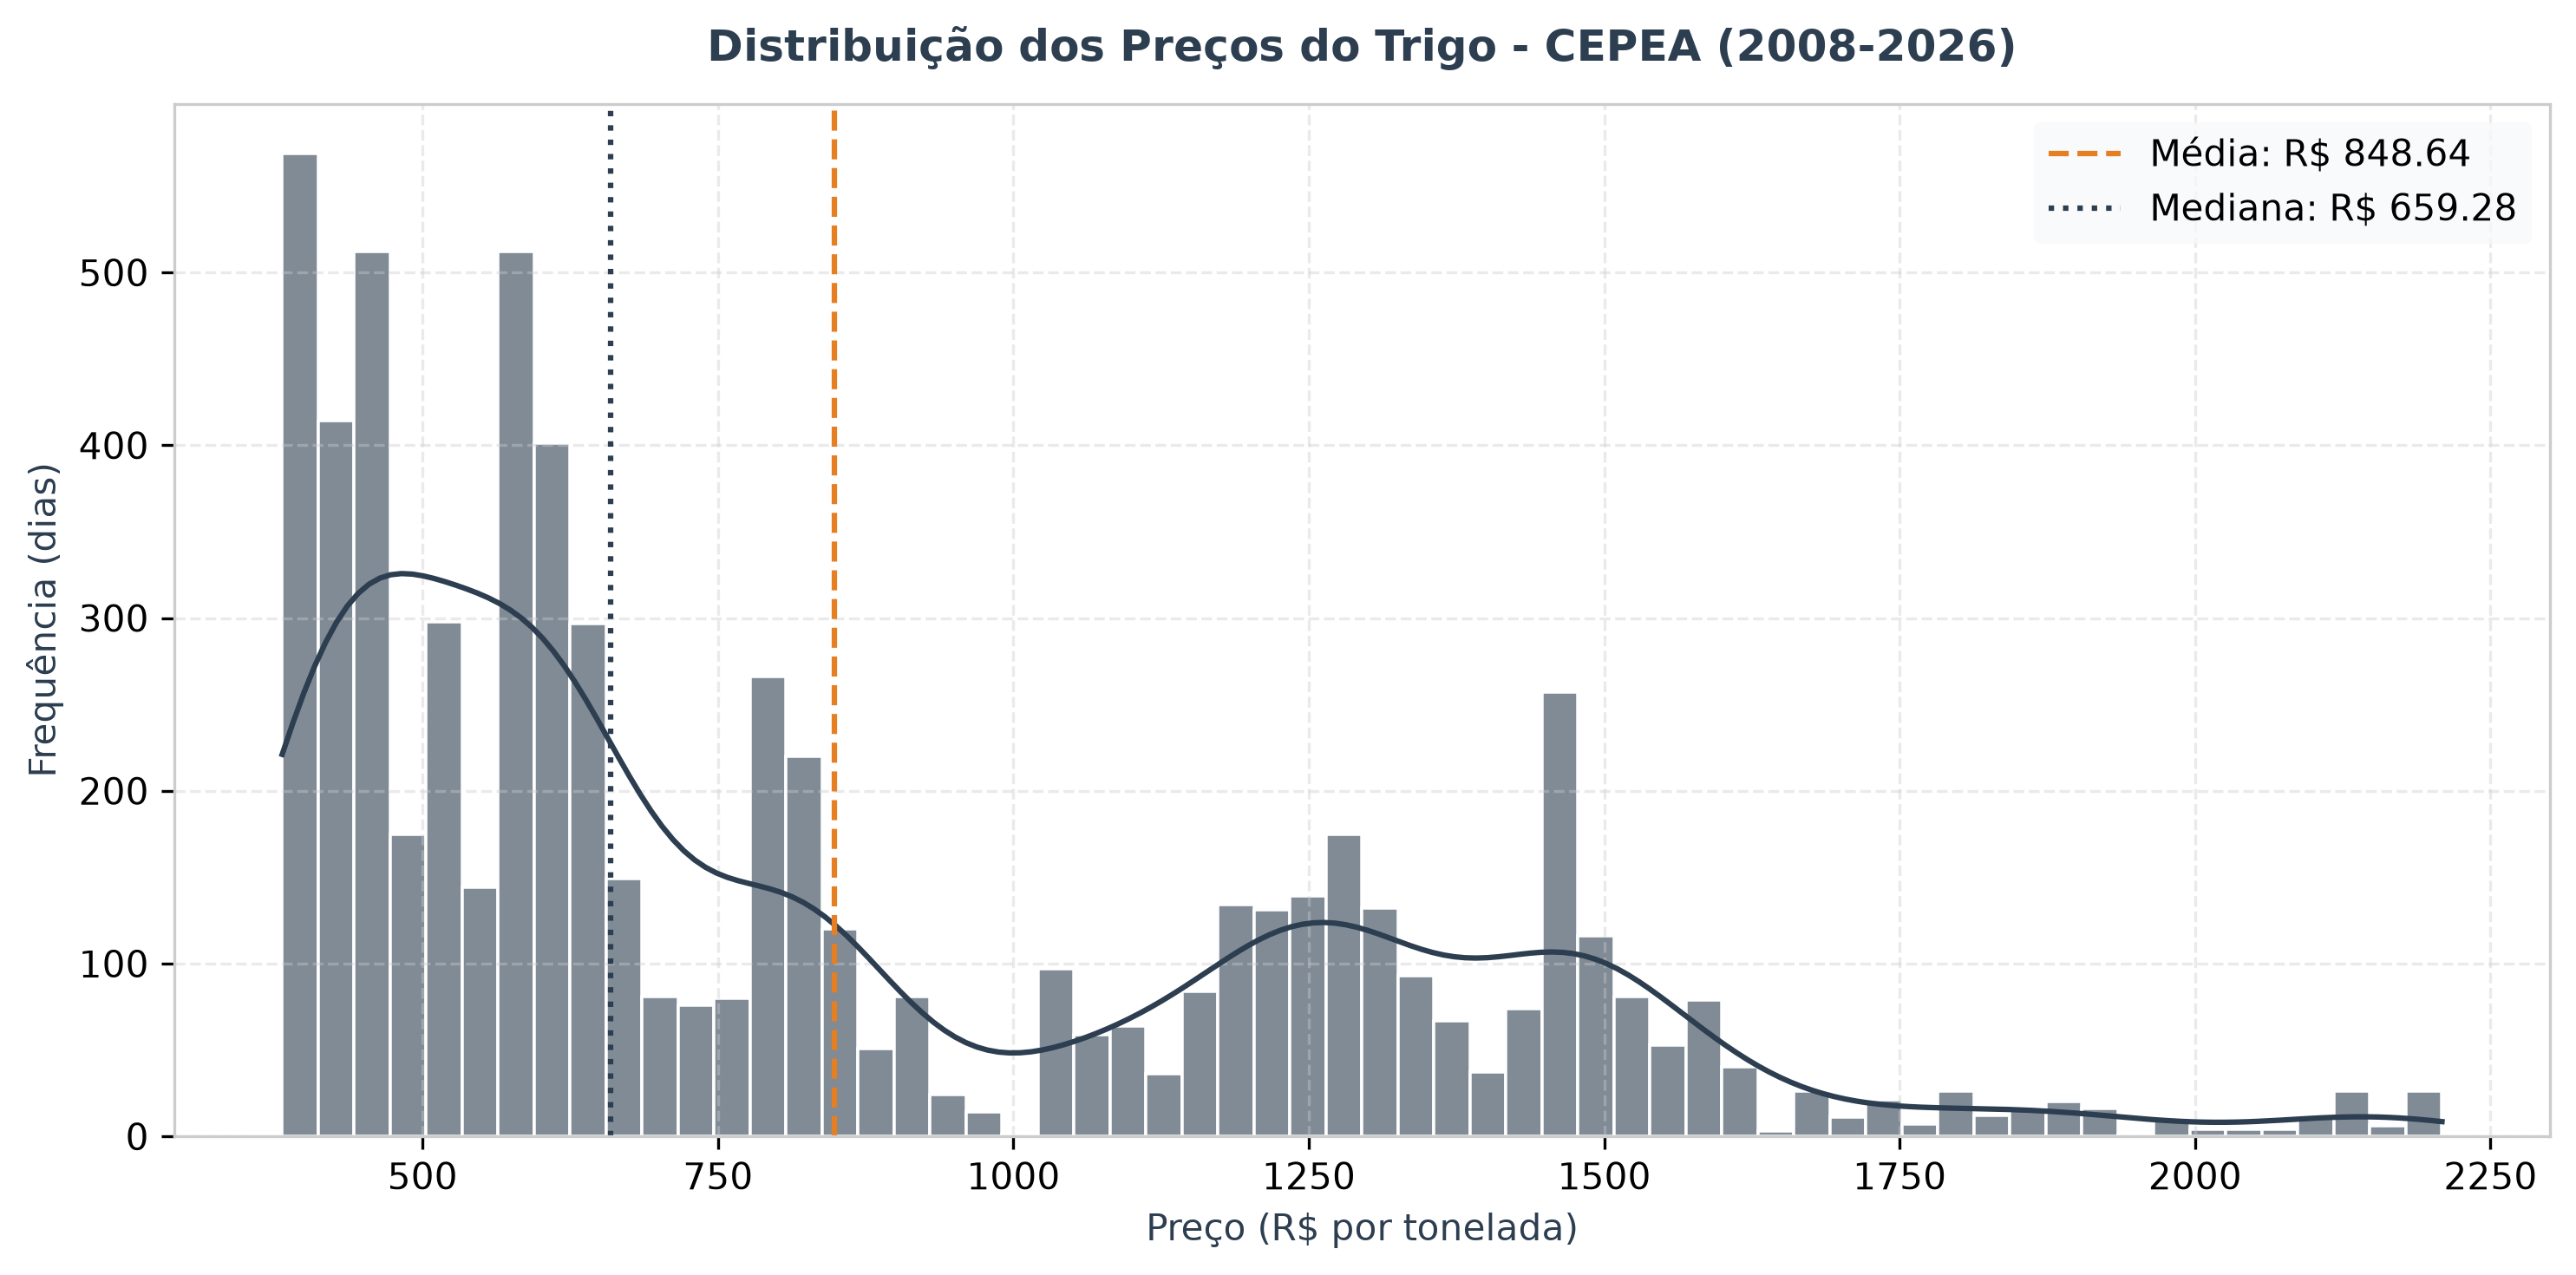

In [7]:
# 1. Tabela de estatísticas descritivas
estatisticas = pd.Series({
    'Observações': len(serie),
    'Média': serie.mean(),
    'Mediana': serie.median(),
    'Desvio Padrão': serie.std(),
    'Coef. de Variação (%)': serie.std() / serie.mean() * 100,
    'Mínimo': serie.min(),
    '1º Quartil (25%)': serie.quantile(0.25),
    '3º Quartil (75%)': serie.quantile(0.75),
    'Máximo': serie.max(),
    'Assimetria (Skewness)': serie.skew(),
    'Curtose (excesso)': serie.kurt(),
}, name='Preço do Trigo (R$/t)')

display(estatisticas.round(2).to_frame())

# 2. Histograma com densidade (KDE) e marcação da média e da mediana
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(serie, bins=60, kde=True, color=ACCENT, edgecolor='white', alpha=0.6, ax=ax)
ax.axvline(serie.mean(), color=ACCENT_SEC, linestyle='--', linewidth=1.5, label=f'Média: R$ {serie.mean():.2f}')
ax.axvline(serie.median(), color=ACCENT, linestyle=':', linewidth=1.5, label=f'Mediana: R$ {serie.median():.2f}')

ax.set_title('Distribuição dos Preços do Trigo - CEPEA (2008-2026)', fontsize=12, pad=12, color=ACCENT, weight='bold')
ax.set_xlabel('Preço (R$ por tonelada)', fontsize=10, color=ACCENT)
ax.set_ylabel('Frequência (dias)', fontsize=10, color=ACCENT)
ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.legend(frameon=True, facecolor=LIGHT, edgecolor='none')

plt.tight_layout()
plt.show()

As estatísticas descritivas e o histograma caracterizam uma distribuição de preços **não-normal e multimodal**, reflexo direto das mudanças de patamar ao longo do tempo:

* **Média versus Mediana:** A média (≈ R$ 849/t) supera com folga a mediana (≈ R$ 659/t). Como metade dos dias teve preço abaixo de R$ 659/t, a média é "puxada" para cima pelos valores elevados do período 2020–2026.
* **Dispersão Elevada:** O desvio padrão (≈ R$ 424/t) corresponde a um coeficiente de variação de aproximadamente **50%**, e o máximo (R$ 2.209/t) é quase seis vezes o mínimo (R$ 381/t).
* **Assimetria Positiva (≈ 0,89):** A cauda direita é mais longa, ou seja, os preços altos são menos frequentes, porém mais extremos — compatível com choques de oferta pontuais e intensos, como o de 2022.
* **Curtose Levemente Negativa (≈ −0,19):** As caudas são um pouco mais "leves" que as de uma normal. Isso não significa ausência de risco: o histograma mostra **vários picos (modas)**, cada um associado a um regime de preços (≈ R$ 380–650/t até 2019, ≈ R$ 770–830/t nos picos de 2018–2019 e ≈ R$ 1.150–1.500/t após 2020). A distribuição é uma mistura de regimes, e não uma única distribuição em torno de uma média estável.

**Implicação para o TCC:** Uma média e uma variância que mudam conforme o período analisado são, por si só, um indício de não-estacionariedade. Além disso, a escala elevada dos preços do trigo (centenas de reais) em relação às demais variáveis do dataset reforça a necessidade de normalização dos dados antes do treinamento da LSTM.

### Análise de Volatilidade e Retornos Percentuais
Para avaliar o grau de risco e a estabilidade da commodity ao longo da série histórica, calcula-se a variação percentual período a período (`pct_change()`). Esta métrica é fundamental para evidenciar os momentos de maior instabilidade e choques de mercado.

**Justificativa Técnica:**
Complementarmente ao gráfico de retornos (no mesmo padrão do arroz), calcula-se a **volatilidade anual** — o desvio padrão dos retornos diários em cada ano —, que permite ranquear objetivamente os anos mais instáveis da série.

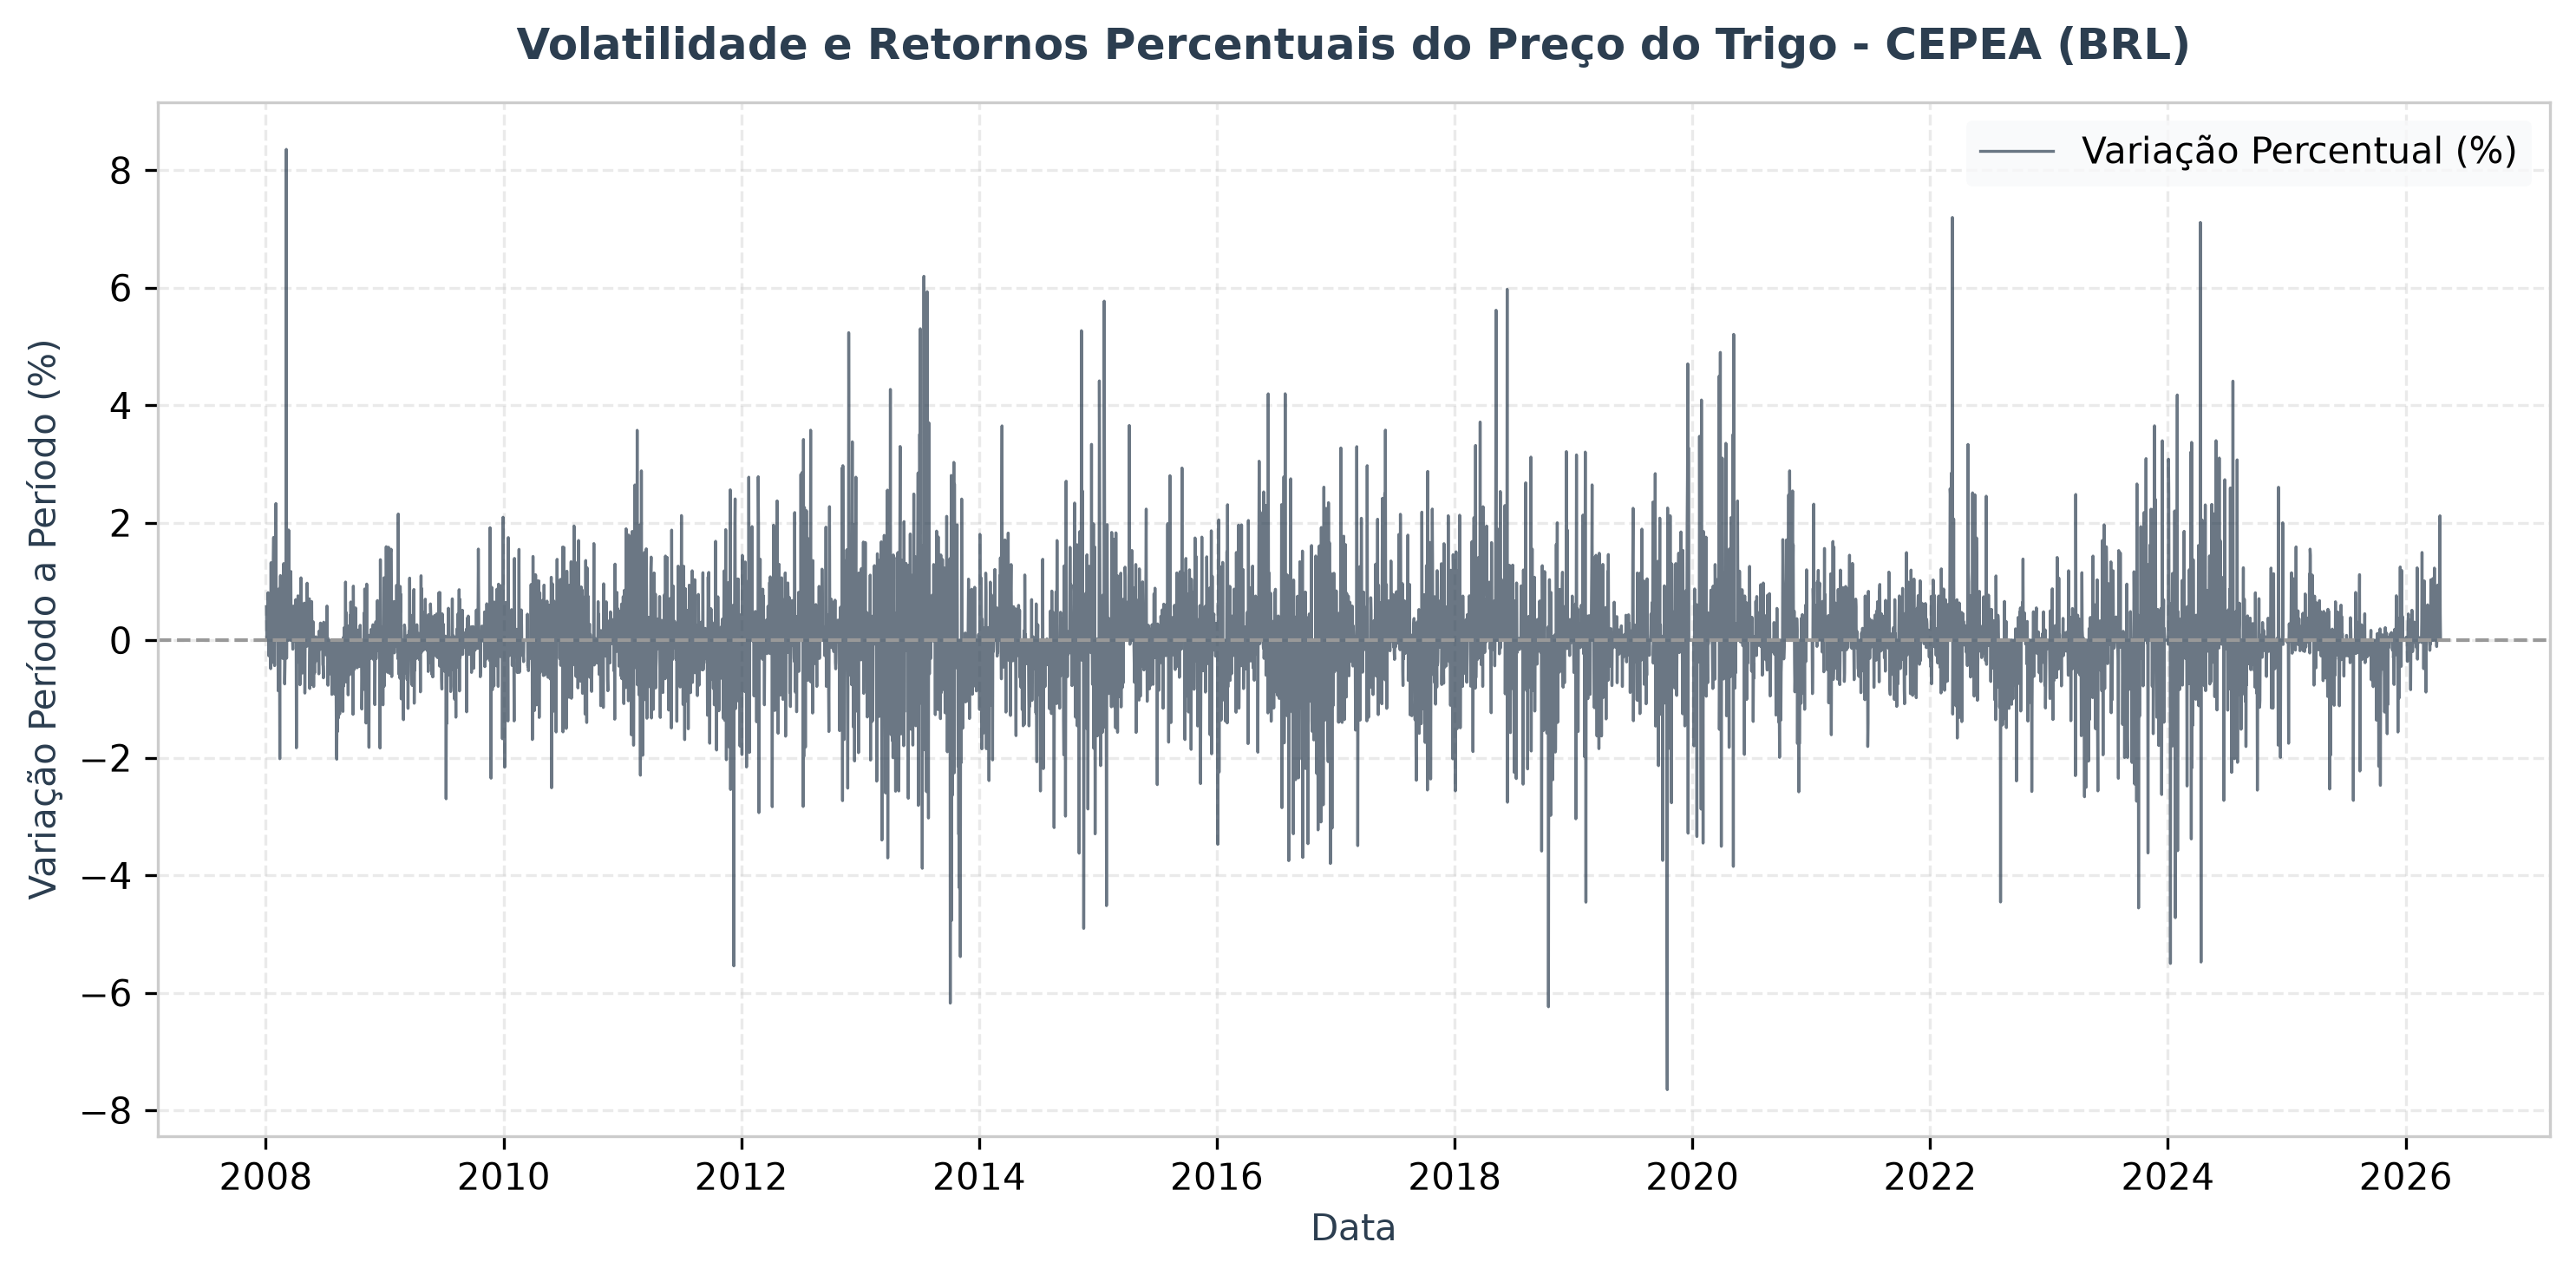

Anos de maior volatilidade:


,Volatilidade diária (%)
data,
2013,1.333
2024,1.100
2016,1.090
2018,1.040
2019,1.002


Maiores variações diárias (em módulo):


,Variação absoluta (%)
data,
2008-03-04,8.35
2019-10-16,7.65
2022-03-10,7.20
2024-04-10,7.11
2018-10-16,6.24
2013-07-15,6.19


In [8]:
# 1. Calculando a variação percentual (retornos) entre os períodos
retornos = serie.pct_change() * 100

# 2. Criando o gráfico de volatilidade dos retornos
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(retornos.index, retornos, color=ACCENT, linewidth=0.8, alpha=0.7, label='Variação Percentual (%)')

ax.set_title('Volatilidade e Retornos Percentuais do Preço do Trigo - CEPEA (BRL)', fontsize=12, pad=12, color=ACCENT, weight='bold')
ax.set_xlabel('Data', fontsize=10, color=ACCENT)
ax.set_ylabel('Variação Período a Período (%)', fontsize=10, color=ACCENT)
ax.axhline(0, color='#999999', linestyle='--', linewidth=1)  # Linha de referência no zero
ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.legend(frameon=True, facecolor=LIGHT, edgecolor='none')

plt.tight_layout()
plt.show()

# 3. Volatilidade anual (desvio padrão dos retornos diários em cada ano)
vol_anual = retornos.groupby(retornos.index.year).std().rename('Volatilidade diária (%)')
print("Anos de maior volatilidade:")
display(vol_anual.sort_values(ascending=False).head(5).round(3).to_frame())

# 4. Maiores variações diárias absolutas da série
print("Maiores variações diárias (em módulo):")
display(retornos.abs().nlargest(6).round(2).rename('Variação absoluta (%)').to_frame())

O gráfico de variações percentuais período a período (`pct_change`) exibe a intensidade das flutuações e a instabilidade dos preços do trigo ao longo de toda a série histórica (2008–2026). A linha tracejada em **0%** atua como uma referência de estabilidade absoluta, onde valores acima indicam alta de preços em relação ao período anterior e valores abaixo indicam queda.

* **Baixa Volatilidade Diária Típica:** Cerca de 95% das variações diárias ficam contidas em ±2%, e o desvio padrão dos retornos em toda a série é de aproximadamente 0,88% ao dia. O mercado físico de trigo, portanto, ajusta preços de forma gradual na maior parte do tempo.
* **Agrupamentos de Volatilidade:** A amplitude das variações não é uniforme. Os anos mais instáveis foram **2013, 2024 e 2016**, seguidos de 2018 e 2019. O ano de 2013 se destaca com folga e coincide com a quebra de safra regional e a restrição de oferta na Argentina, principal fornecedora de trigo do Brasil.
* **Choques Pontuais:** As maiores variações diárias aparecem isoladas, como "picos" que não se propagam — característica de *outliers* nos retornos. Entre elas, a alta de ≈ 7,2% em 10/03/2022 coincide com as primeiras semanas da guerra entre Rússia e Ucrânia. As demais (como ≈ 8,4% em março de 2008 e ≈ 7,7% em outubro de 2019) refletem ajustes bruscos de cotação no mercado físico gaúcho, muitas vezes após vários dias sem alteração de preço.
* **Comportamento da Série:** A volatilidade condicional muda ao longo do tempo (períodos calmos alternados com períodos turbulentos), fenômeno conhecido como **heterocedasticidade condicional**.

**Implicação para o TCC:** A variância não constante reforça a não-estacionariedade e indica que os intervalos de confiança dos modelos lineares tendem a ser subestimados nos períodos de crise. Modelos não-lineares como a LSTM, que aprendem diretamente com as janelas recentes, são candidatos naturais a capturar essas mudanças de regime.

## 3. Análise de Estacionariedade (Testes Estatísticos)

### Fundamentação Teórica
Uma série temporal é **(fracamente) estacionária** quando sua média, sua variância e sua estrutura de autocovariância são constantes ao longo do tempo. Essa propriedade é um pré-requisito dos modelos ARMA: se ela não é atendida, as estimativas podem gerar **regressões espúrias** e previsões sem fundamento estatístico.

Para diagnosticar a estacionariedade, aplicam-se dois testes com **hipóteses nulas opostas**, de modo que um confirme o outro:

| Teste | Hipótese Nula ($H_0$) | Hipótese Alternativa ($H_1$) | Evidência de estacionariedade |
|---|---|---|---|
| **ADF** (Augmented Dickey-Fuller) | A série possui raiz unitária (**não estacionária**) | A série é estacionária | p-value **< 0,05** (rejeita $H_0$) |
| **KPSS** (Kwiatkowski-Phillips-Schmidt-Shin) | A série é **estacionária** | A série possui raiz unitária | p-value **> 0,05** (não rejeita $H_0$) |

O teste ADF estima a regressão $\Delta Y_t = \alpha + \gamma Y_{t-1} + \sum_{i=1}^{k} \beta_i \Delta Y_{t-i} + \varepsilon_t$ e testa se $\gamma = 0$ (raiz unitária). O número de defasagens $k$ é escolhido automaticamente pelo critério de informação de Akaike (AIC).

**Regra de decisão conjunta:** a série é considerada estacionária quando o **ADF rejeita** e o **KPSS não rejeita** $H_0$. Se a série em nível ($Y_t$) for não estacionária e a primeira diferença ($\Delta Y_t = Y_t - Y_{t-1}$) for estacionária, a série é **integrada de ordem 1**, ou $I(1)$, o que define o parâmetro $d = 1$ dos modelos ARIMA/SARIMA.

### Aplicação dos Testes ADF e KPSS (Nível e Primeira Diferença)
**Justificativa Técnica:**
A função `testar_estacionariedade()` encapsula os dois testes e devolve os resultados em uma tabela padronizada, aplicada tanto à série em nível quanto à série em primeira diferença. Utiliza-se `regression='c'` (constante) em ambos os testes. Observação: o `statsmodels` interpola o p-value do KPSS em uma tabela limitada ao intervalo [0,01; 0,10]; quando a estatística fica fora dessa faixa, o p-value exibido é o limite da tabela (o valor real é **menor que 0,01** ou **maior que 0,10**).

In [9]:
def testar_estacionariedade(x, nome):
    """Aplica os testes ADF e KPSS e retorna um resumo padronizado."""
    adf_stat, adf_p, adf_lags, _, adf_crit, _ = adfuller(x, autolag='AIC', regression='c')
    kpss_stat, kpss_p, kpss_lags, kpss_crit = kpss(x, regression='c', nlags='auto')

    return pd.DataFrame({
        'Série': [nome, nome],
        'Teste': ['ADF', 'KPSS'],
        'Estatística': [adf_stat, kpss_stat],
        'Valor Crítico (5%)': [adf_crit['5%'], kpss_crit['5%']],
        'p-value': [adf_p, kpss_p],
        'Defasagens': [adf_lags, kpss_lags],
        'Conclusão (5%)': [
            'Estacionária' if adf_p < 0.05 else 'Não estacionária (raiz unitária)',
            'Estacionária' if kpss_p > 0.05 else 'Não estacionária',
        ],
    })


# Série em nível (Y_t) e em primeira diferença (ΔY_t)
serie_diff = serie.diff().dropna()

resultados = pd.concat([
    testar_estacionariedade(serie, 'Nível (Y_t)'),
    testar_estacionariedade(serie_diff, '1ª Diferença (ΔY_t)'),
], ignore_index=True)

display(resultados.style.format({
    'Estatística': '{:.4f}', 'Valor Crítico (5%)': '{:.4f}', 'p-value': '{:.4g}'
}).hide(axis='index'))

Série,Teste,Estatística,Valor Crítico (5%),p-value,Defasagens,Conclusão (5%)
Nível (Y_t),ADF,-1.3307,-2.8620,0.615,21,Não estacionária (raiz unitária)
Nível (Y_t),KPSS,9.7903,0.4630,0.01,51,Não estacionária
1ª Diferença (ΔY_t),ADF,-13.4302,-2.8620,4.028e-25,20,Estacionária
1ª Diferença (ΔY_t),KPSS,0.0769,0.4630,0.1,35,Estacionária


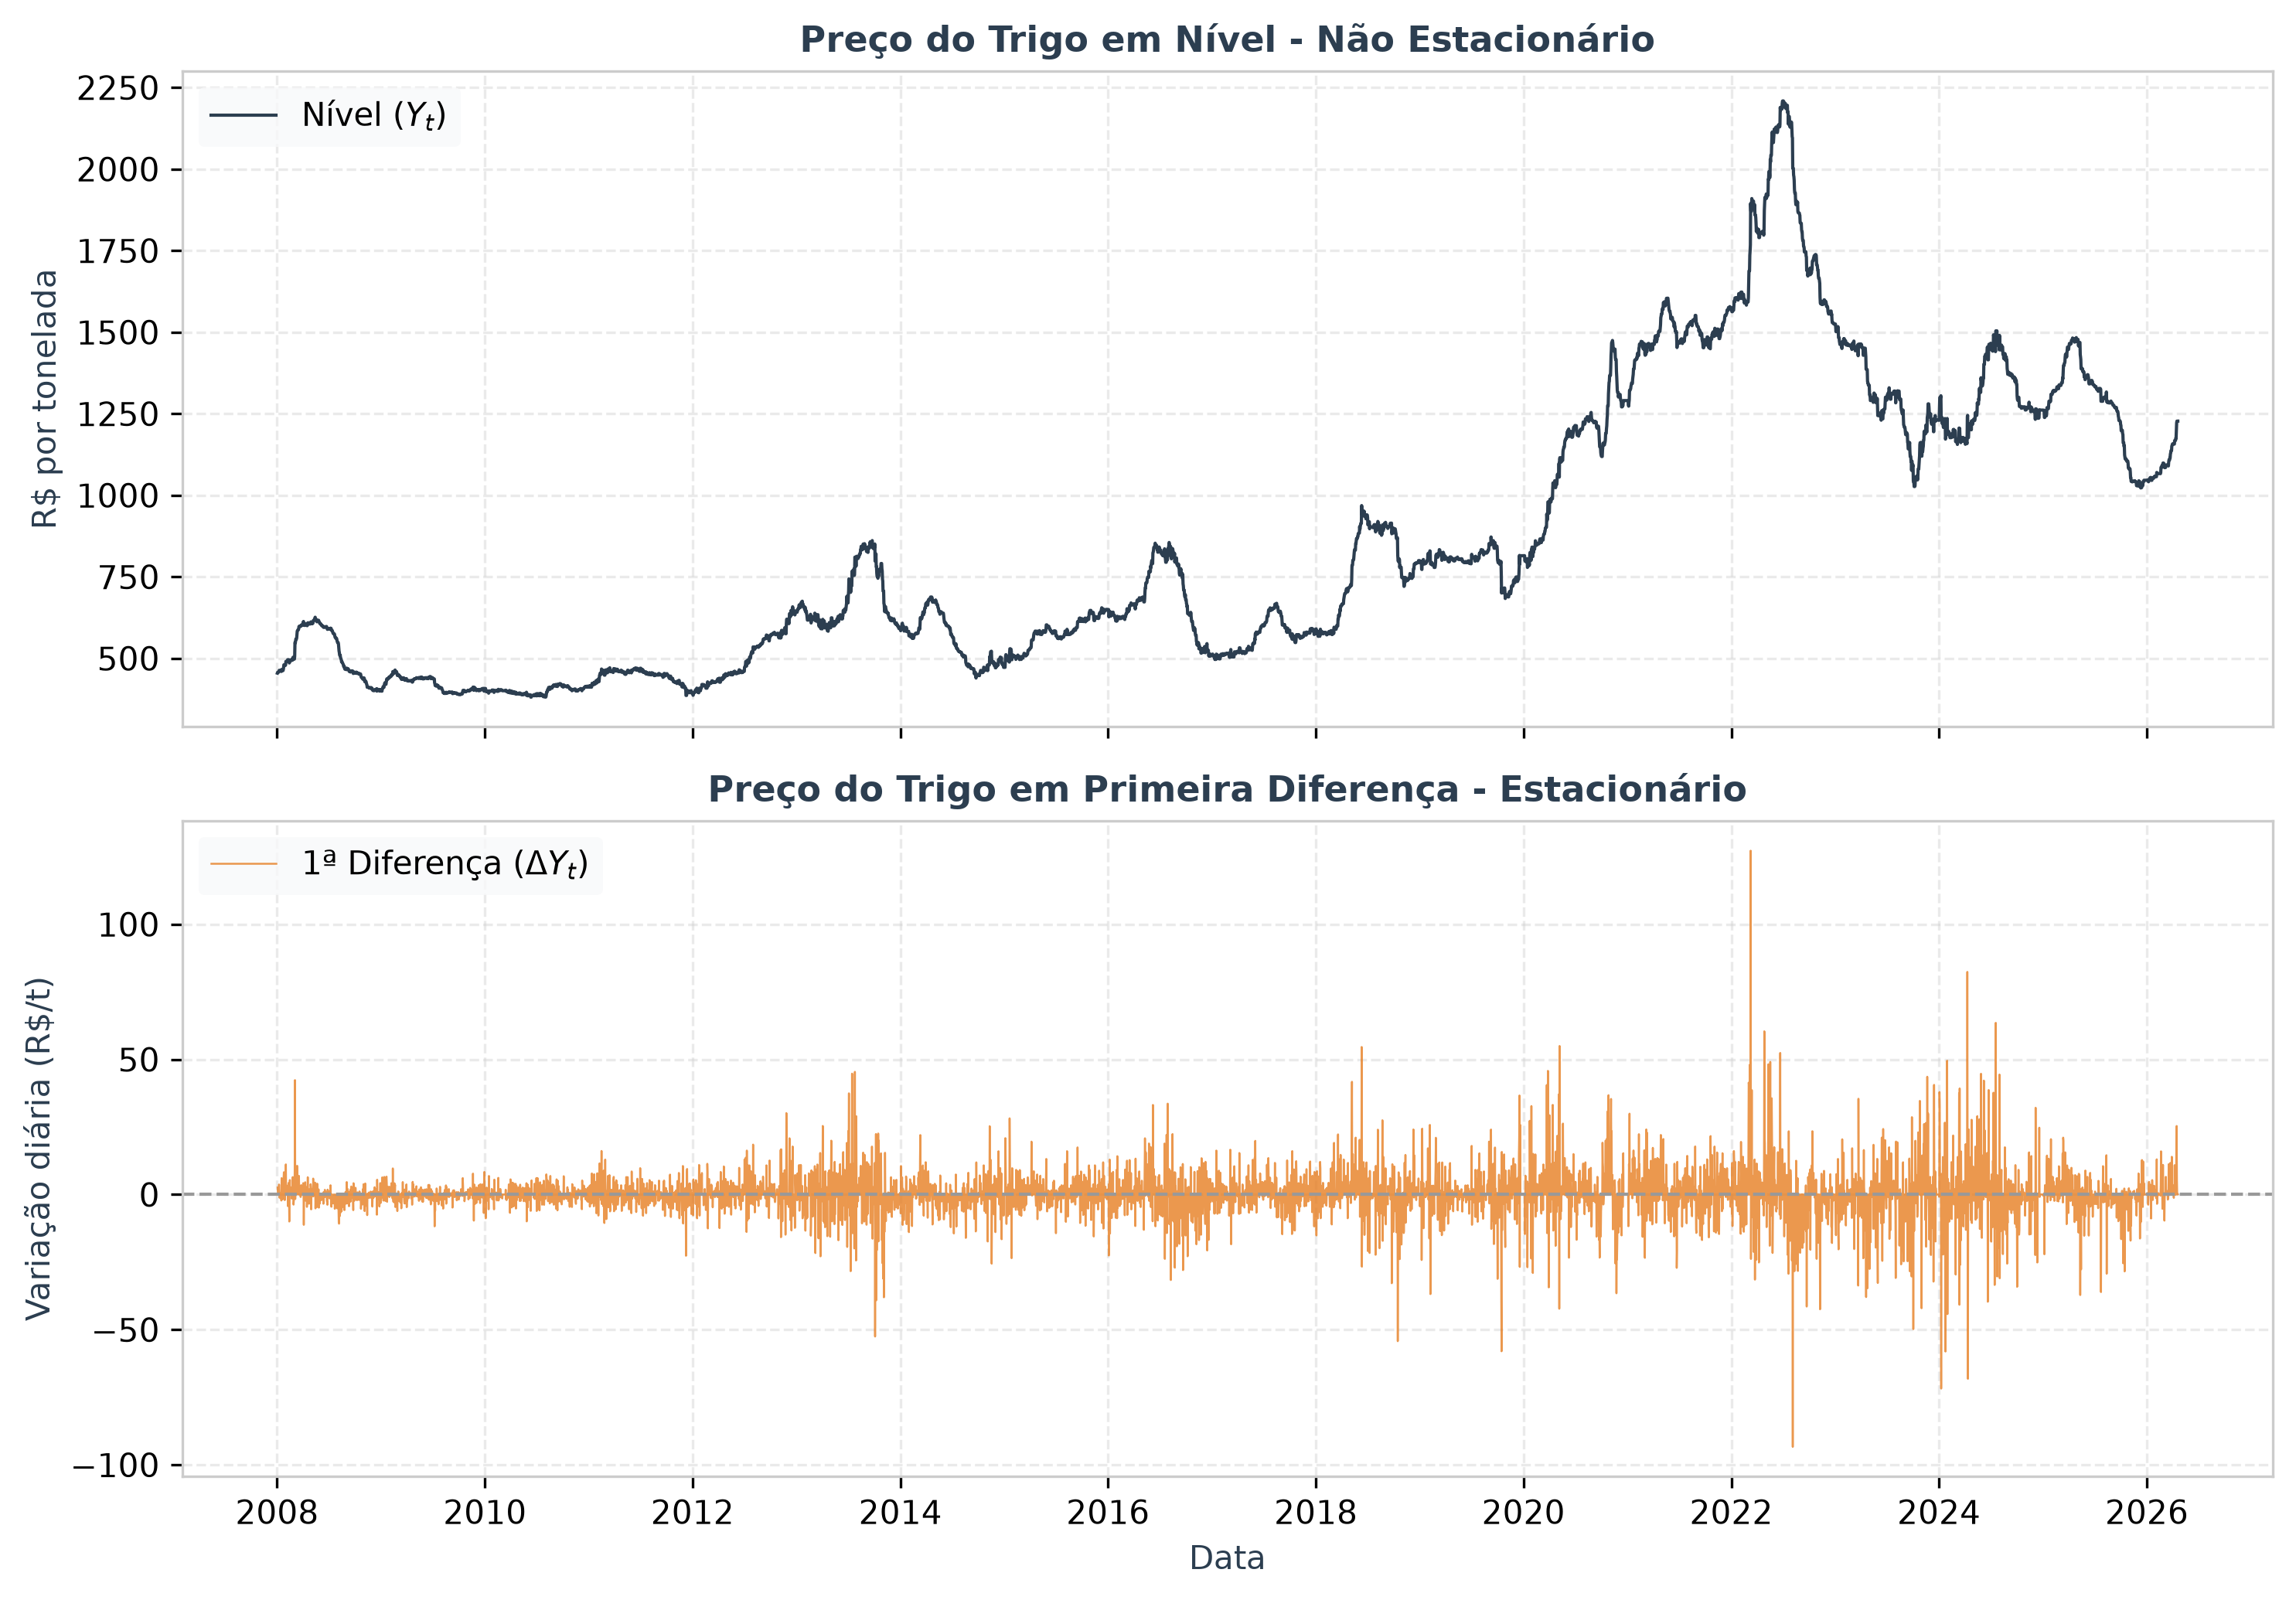

In [10]:
# Visualização comparativa: série em nível versus série em primeira diferença
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(serie.index, serie, color=ACCENT, linewidth=1.0, label='Nível ($Y_t$)')
axes[0].set_title('Preço do Trigo em Nível - Não Estacionário', fontsize=11, color=ACCENT, weight='bold')
axes[0].set_ylabel('R$ por tonelada', fontsize=10, color=ACCENT)

axes[1].plot(serie_diff.index, serie_diff, color=ACCENT_SEC, linewidth=0.6, alpha=0.8, label=r'1ª Diferença ($\Delta Y_t$)')
axes[1].axhline(0, color='#999999', linestyle='--', linewidth=1)
axes[1].set_title('Preço do Trigo em Primeira Diferença - Estacionário', fontsize=11, color=ACCENT, weight='bold')
axes[1].set_ylabel('Variação diária (R$/t)', fontsize=10, color=ACCENT)
axes[1].set_xlabel('Data', fontsize=10, color=ACCENT)

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
    ax.legend(frameon=True, facecolor=LIGHT, edgecolor='none', loc='upper left')

plt.tight_layout()
plt.show()

Os resultados dos testes são conclusivos e convergentes:

* **Série em Nível ($Y_t$):**
  * **ADF:** estatística ≈ −1,33, acima do valor crítico de 5% (≈ −2,86), com **p-value ≈ 0,62**. Não é possível rejeitar $H_0$: há evidência de **raiz unitária**.
  * **KPSS:** estatística ≈ 9,79, muito acima do valor crítico de 5% (0,463), com **p-value < 0,01**. Rejeita-se $H_0$ de estacionariedade.
  * Ambos os testes apontam na mesma direção: a série de preços em nível é **não estacionária**, o que confirma o que os gráficos já sugeriam (tendência e mudanças de patamar).
* **Série em Primeira Diferença ($\Delta Y_t$):**
  * **ADF:** estatística ≈ −13,43, muito abaixo do valor crítico, com **p-value da ordem de $10^{-25}$**. Rejeita-se $H_0$ com ampla margem: não há raiz unitária.
  * **KPSS:** estatística ≈ 0,08, abaixo do valor crítico de 5%, com **p-value > 0,10**. Não se rejeita $H_0$ de estacionariedade.
  * Após uma única diferenciação, a série oscila em torno de zero sem tendência, conforme mostra o painel inferior do gráfico.

**Conclusão Estatística:** como a série é não estacionária em nível e estacionária em primeira diferença, o preço do trigo é **integrado de ordem 1, $I(1)$**. Na prática, isso significa que os choques de preço têm efeito **permanente** (o preço não "volta" para uma média fixa), enquanto as **variações diárias** são estáveis ao longo do tempo.

**Implicação para o TCC:** os modelos SARIMA e SARIMAX devem ser especificados com **$d = 1$**, exatamente como no caso do arroz. Uma segunda diferenciação ($d = 2$) não é necessária e seria contraproducente (sobrediferenciação introduz autocorrelação negativa artificial). Observa-se ainda, no painel inferior, que a amplitude das variações cresce a partir de 2020 — a diferença remove a tendência na média, mas não elimina totalmente a heterocedasticidade identificada na Seção 2.

## 4. Decomposição da Série Temporal

### Decomposição Aditiva: Tendência, Sazonalidade e Resíduos
A decomposição clássica separa a série observada em componentes não observáveis. No modelo **aditivo**:

$$Y_t = T_t + S_t + R_t$$

em que $T_t$ é a **tendência** (movimento de longo prazo), $S_t$ é a **sazonalidade** (padrão que se repete a cada período $s$) e $R_t$ são os **resíduos** (componente irregular, não explicada pelas demais).

**Justificativa Técnica:**
Utiliza-se `seasonal_decompose` do `statsmodels` com `period=365`, pois a série possui frequência diária em calendário contínuo e o interesse é o ciclo **anual** da safra. A tendência é estimada por uma média móvel centrada de 365 dias, o que faz com que os primeiros e os últimos ~6 meses da tendência e dos resíduos fiquem indefinidos (comportamento esperado do método). O modelo aditivo expressa a sazonalidade em **R$/t**, unidade diretamente interpretável. Como a amplitude dos preços aumenta com o nível, uma alternativa seria o modelo multiplicativo (ou a decomposição do logaritmo dos preços); a versão aditiva é mantida aqui por padronização com a análise do arroz e pela facilidade de leitura.

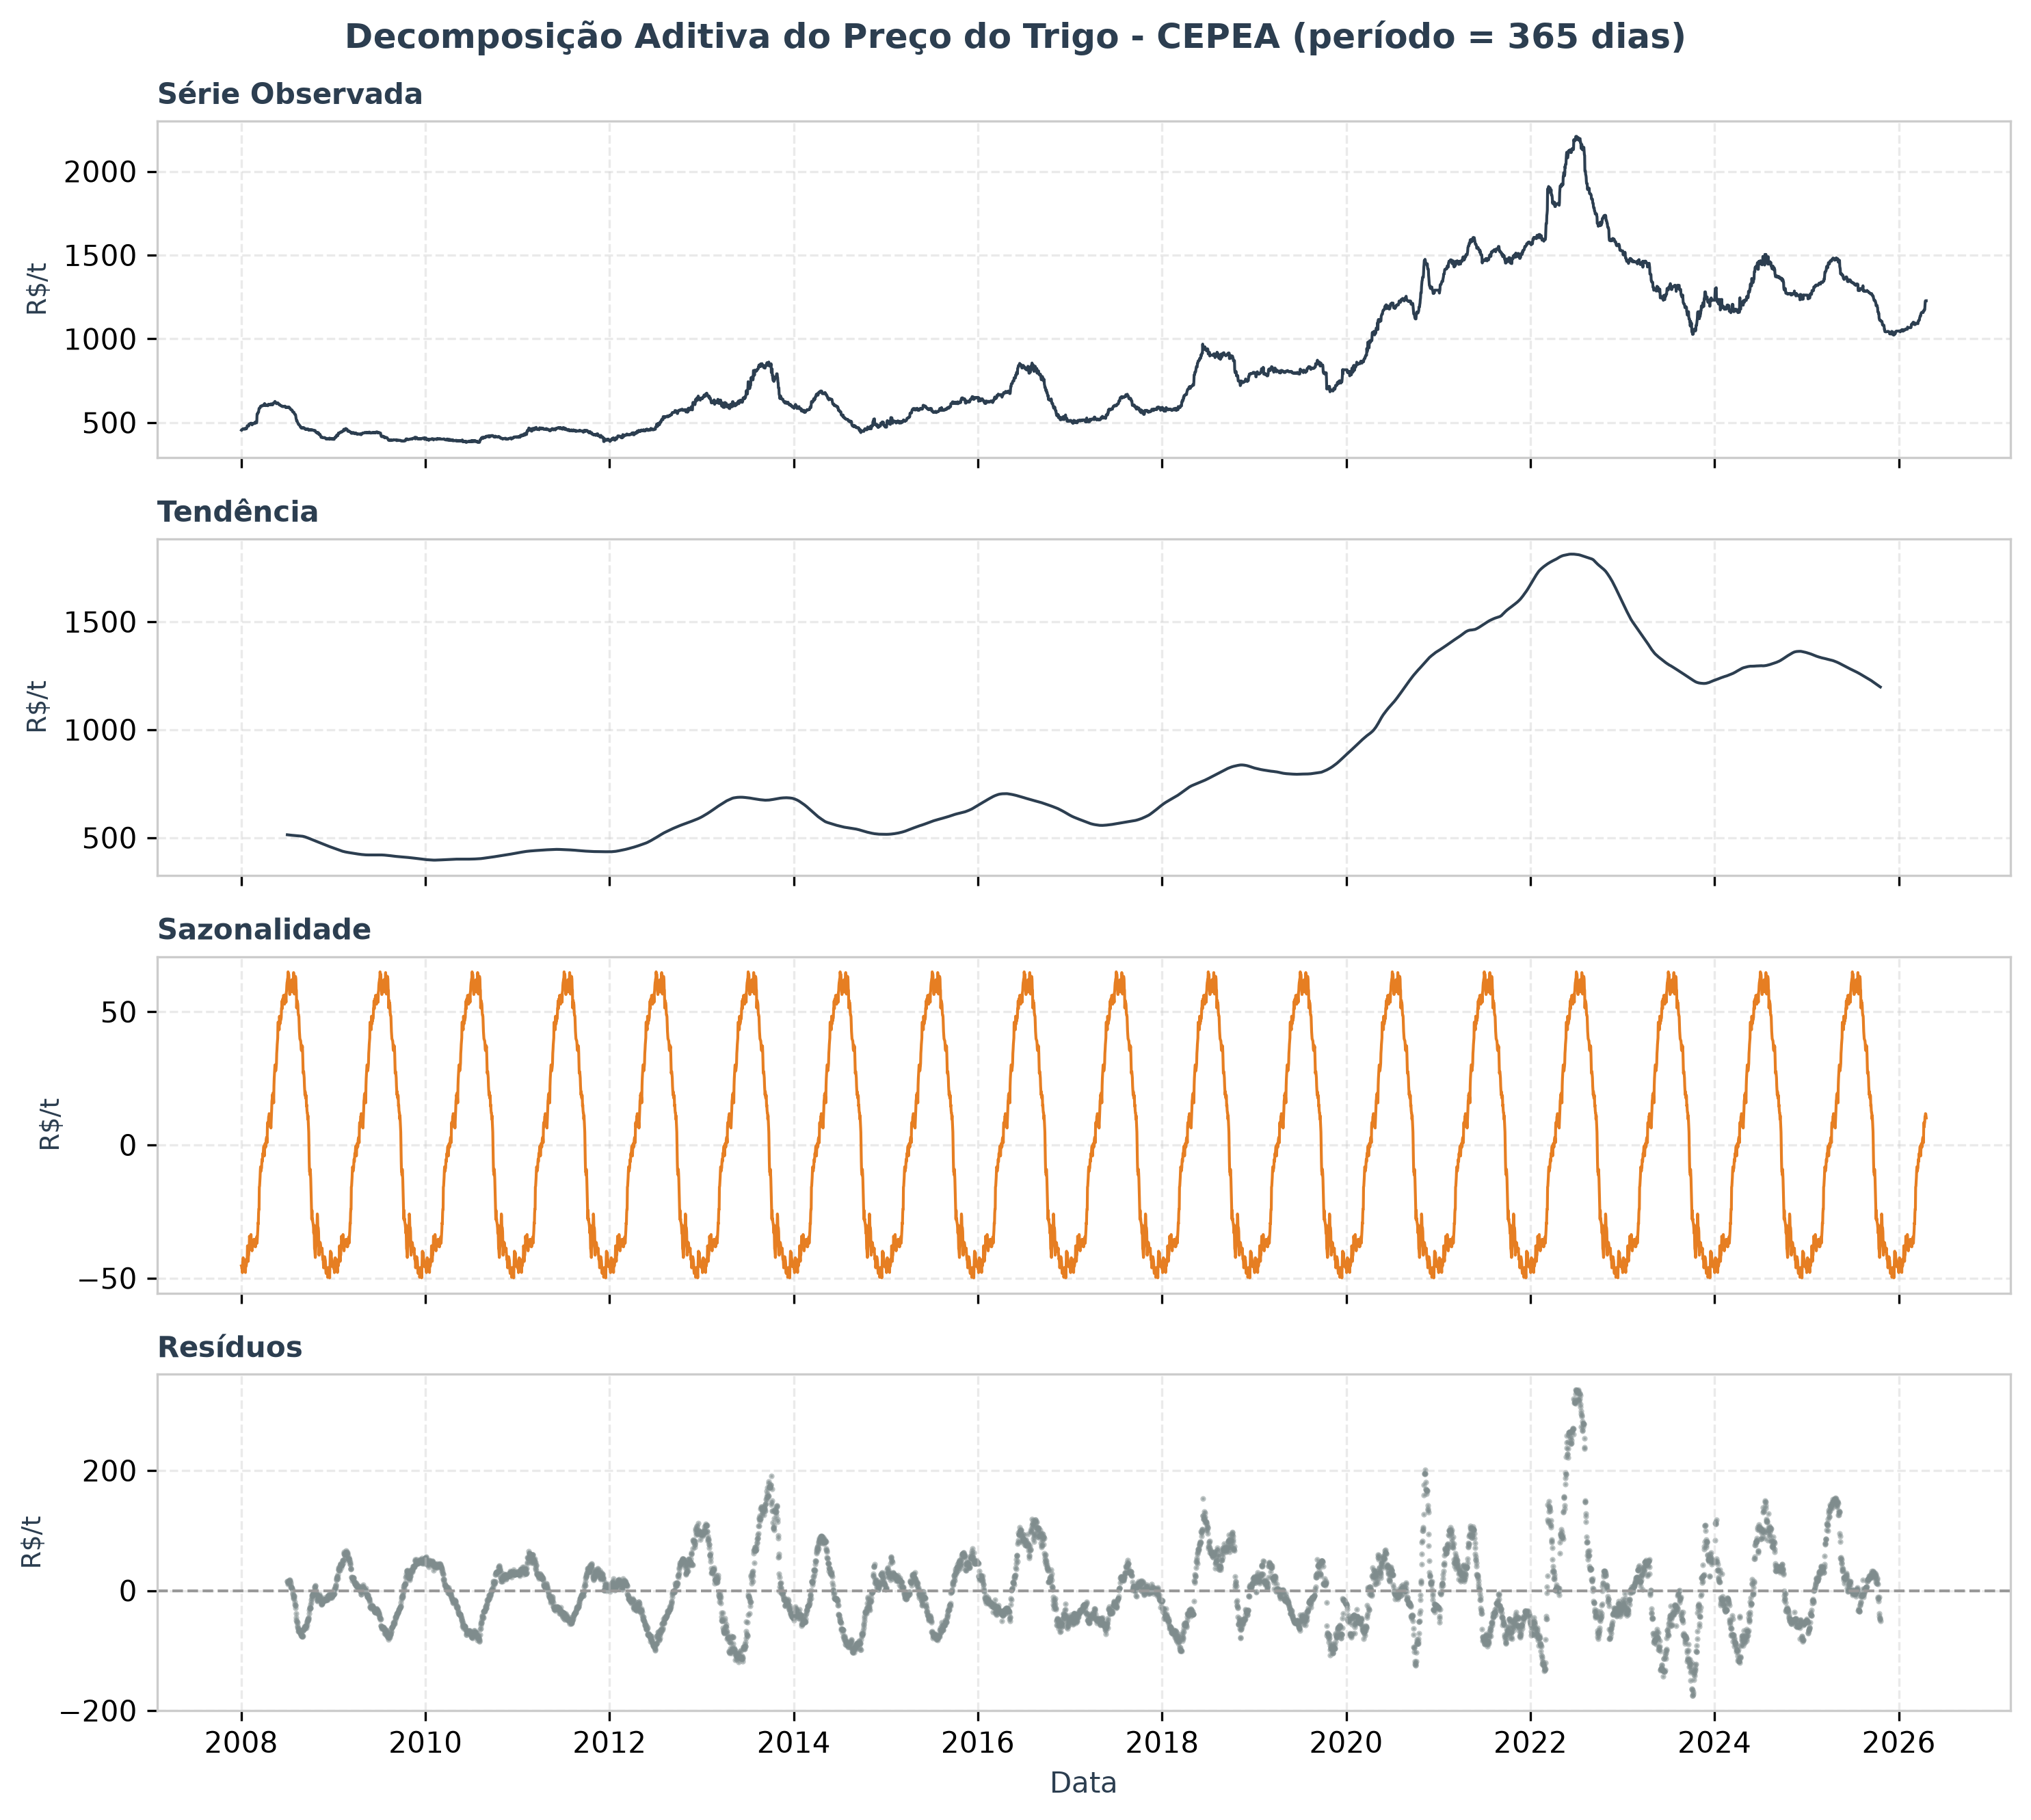

Tendência: de R$ 395.88 a R$ 1812.86 por tonelada
Sazonalidade: de R$ -49.91 a R$ 64.98 (amplitude de R$ 114.89)
Desvio padrão dos resíduos: R$ 64.74


In [11]:
# Decomposição aditiva com ciclo anual (365 dias corridos)
decomposicao = seasonal_decompose(serie, model='additive', period=365)

componentes = [
    (decomposicao.observed, 'Série Observada', ACCENT),
    (decomposicao.trend, 'Tendência', ACCENT),
    (decomposicao.seasonal, 'Sazonalidade', ACCENT_SEC),
    (decomposicao.resid, 'Resíduos', '#7f8c8d'),
]

fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)

for ax, (comp, titulo, cor) in zip(axes, componentes):
    if titulo == 'Resíduos':
        ax.scatter(comp.index, comp, s=1, color=cor, alpha=0.5)
        ax.axhline(0, color='#999999', linestyle='--', linewidth=1)
    else:
        ax.plot(comp.index, comp, color=cor, linewidth=1.0)
    ax.set_title(titulo, fontsize=10, color=ACCENT, weight='bold', loc='left')
    ax.set_ylabel('R$/t', fontsize=9, color=ACCENT)
    ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc')

axes[-1].set_xlabel('Data', fontsize=10, color=ACCENT)
fig.suptitle('Decomposição Aditiva do Preço do Trigo - CEPEA (período = 365 dias)', fontsize=12, color=ACCENT, weight='bold')

plt.tight_layout()
plt.show()

# Resumo quantitativo das componentes
print(f"Tendência: de R$ {decomposicao.trend.min():.2f} a R$ {decomposicao.trend.max():.2f} por tonelada")
print(f"Sazonalidade: de R$ {decomposicao.seasonal.min():.2f} a R$ {decomposicao.seasonal.max():.2f} "
      f"(amplitude de R$ {decomposicao.seasonal.max() - decomposicao.seasonal.min():.2f})")
print(f"Desvio padrão dos resíduos: R$ {decomposicao.resid.std():.2f}")

### Componente Sazonal Média por Mês
Para traduzir a componente sazonal diária em uma leitura agronômica, calcula-se o efeito sazonal médio de cada mês do ano. Valores positivos indicam meses em que o preço tende a ficar **acima** da tendência; valores negativos, meses em que tende a ficar **abaixo**.

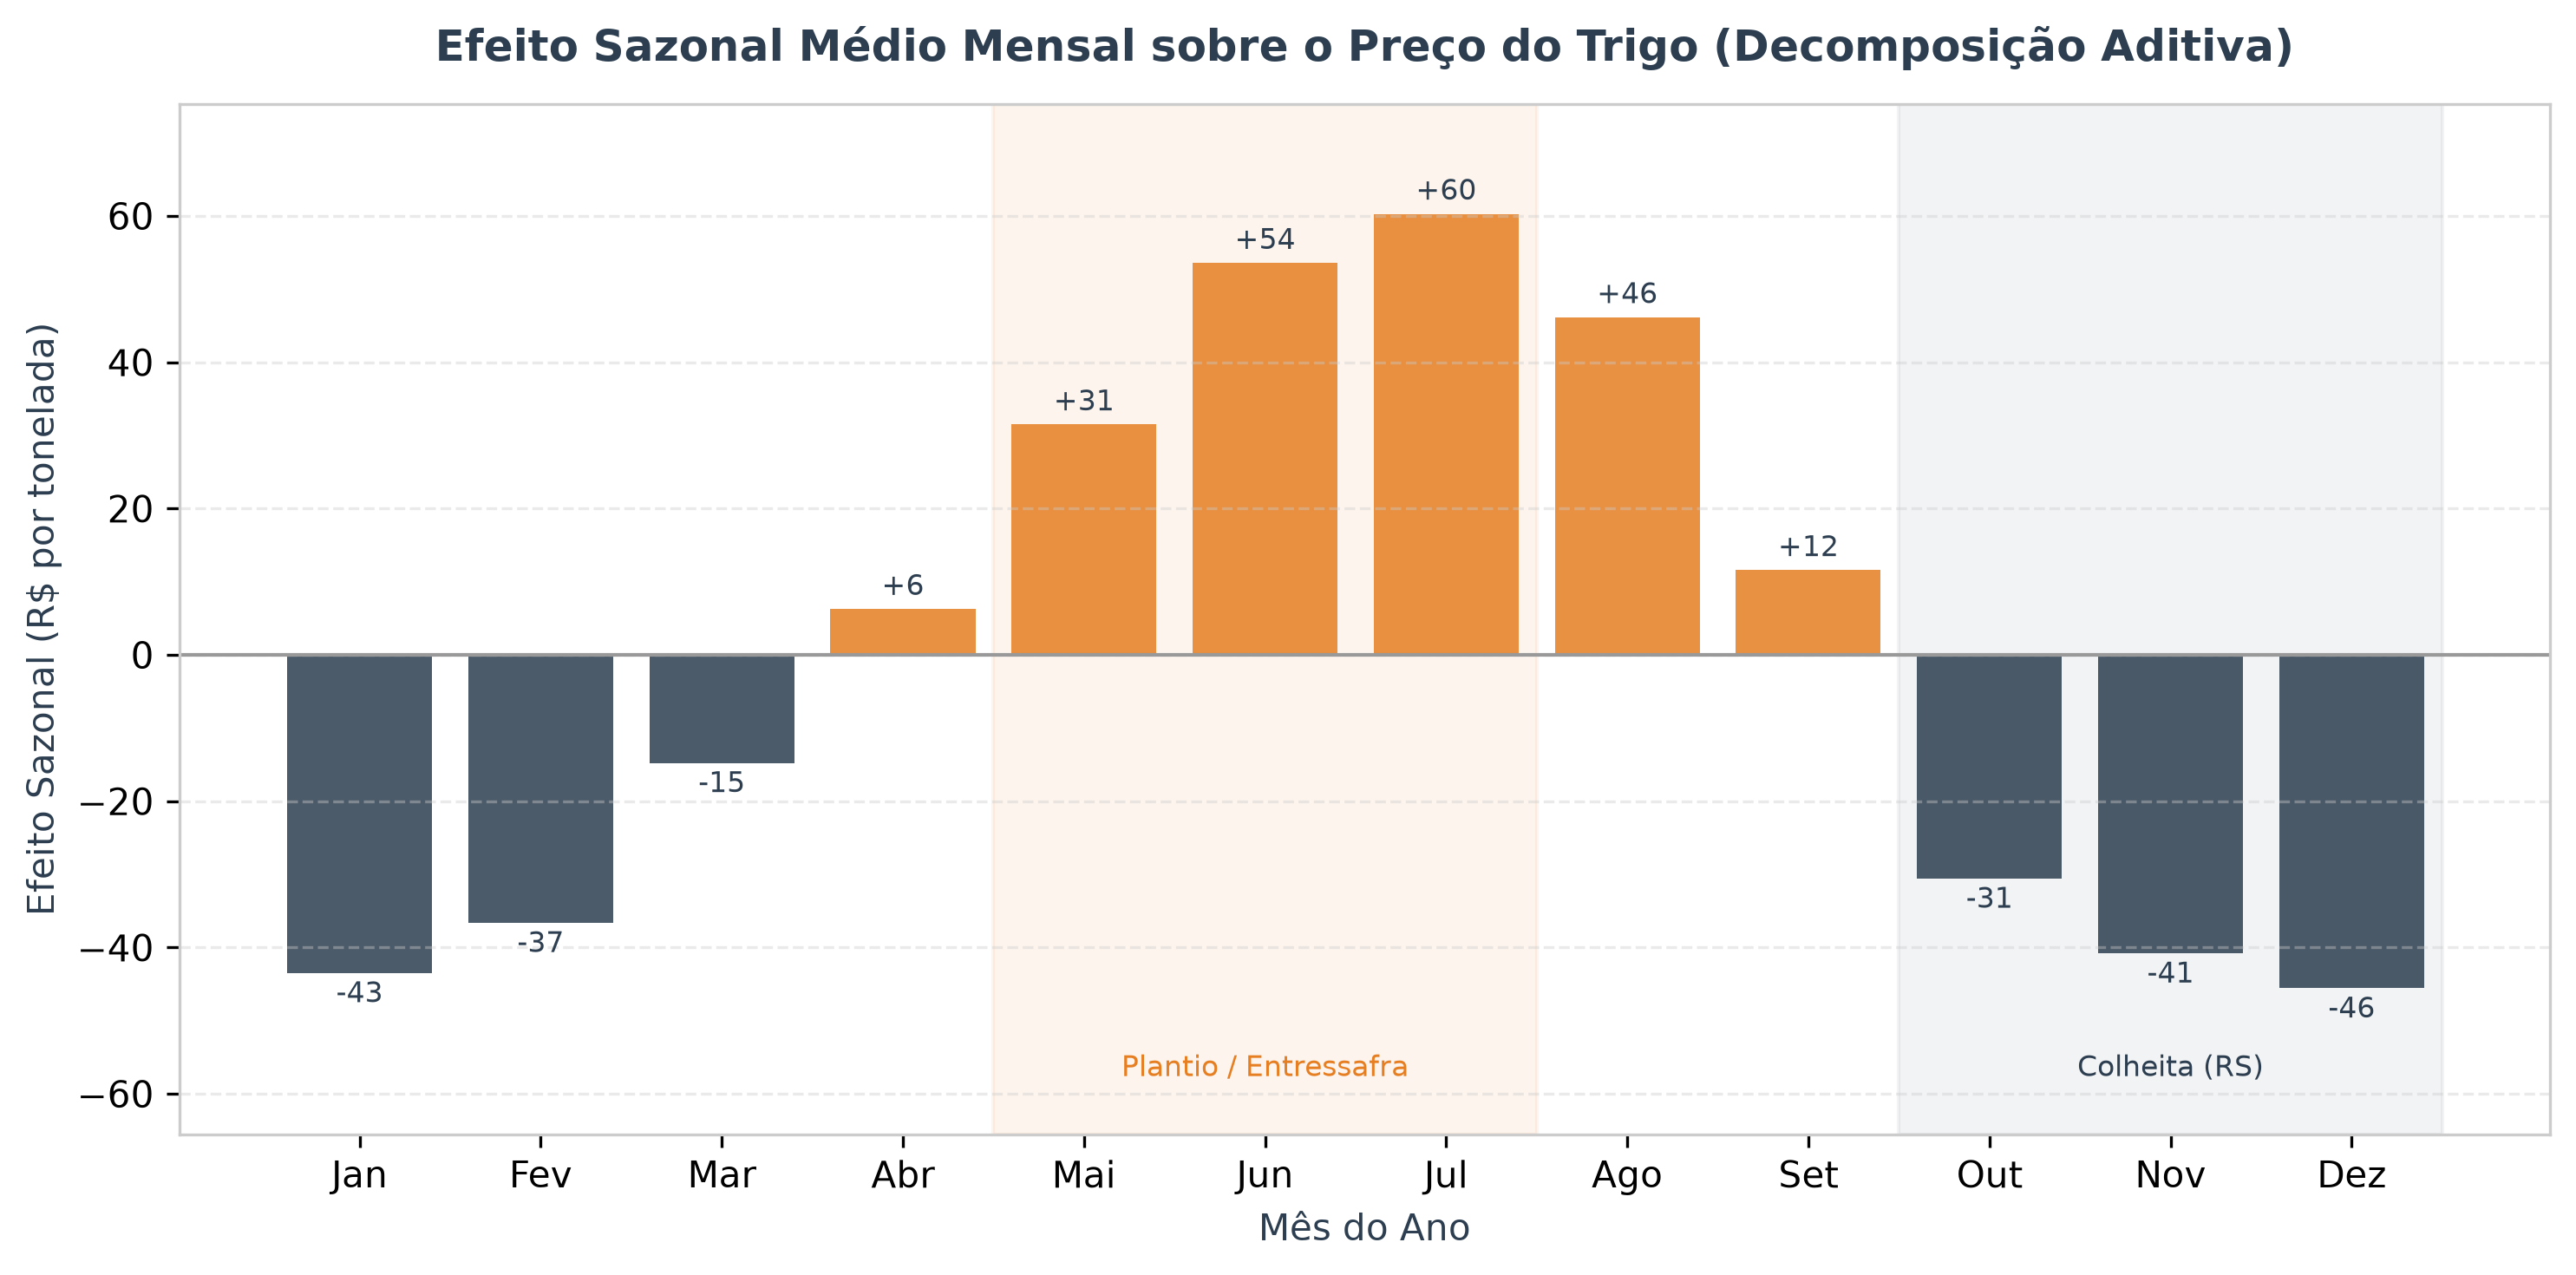

In [12]:
# Efeito sazonal médio por mês (R$/t em relação à tendência)
efeito_mensal = decomposicao.seasonal.groupby(decomposicao.seasonal.index.month).mean()

cores = [ACCENT_SEC if v > 0 else ACCENT for v in efeito_mensal]

fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.bar(efeito_mensal.index, efeito_mensal.values, color=cores, alpha=0.85)
ax.bar_label(barras, fmt='%+.0f', fontsize=8, color=ACCENT, padding=2)
ax.axhline(0, color='#999999', linewidth=1)

# Faixas do calendário agrícola da safra de inverno no Rio Grande do Sul
ax.axvspan(4.5, 7.5, color=ACCENT_SEC, alpha=0.08)
ax.axvspan(9.5, 12.5, color=ACCENT, alpha=0.06)
ax.text(6, efeito_mensal.min() - 12, 'Plantio / Entressafra', ha='center', fontsize=8, color=ACCENT_SEC)
ax.text(11, efeito_mensal.min() - 12, 'Colheita (RS)', ha='center', fontsize=8, color=ACCENT)

ax.set_title('Efeito Sazonal Médio Mensal sobre o Preço do Trigo (Decomposição Aditiva)', fontsize=12, pad=12, color=ACCENT, weight='bold')
ax.set_xlabel('Mês do Ano', fontsize=10, color=ACCENT)
ax.set_ylabel('Efeito Sazonal (R$ por tonelada)', fontsize=10, color=ACCENT)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES_NOMES)
ax.set_ylim(efeito_mensal.min() - 20, efeito_mensal.max() + 15)
ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc', axis='y')

plt.tight_layout()
plt.show()

A decomposição evidencia três comportamentos distintos:

* **Tendência:** concentra a maior parte da variação da série, subindo de ≈ R$ 396/t (início de 2010) para ≈ R$ 1.813/t em meados de 2022, com posterior acomodação. É essa componente que torna a série não estacionária, confirmando os testes da Seção 3.
* **Sazonalidade:** apresenta um ciclo anual nítido e bem definido, com amplitude de aproximadamente **R$ 115/t** entre o pico e o vale. O efeito é **positivo de abril a setembro**, com máximo em **julho (≈ +R$ 60/t)**, e **negativo de outubro a março**, com mínimo em **dezembro e janeiro (≈ −R$ 45/t)**.
* **Resíduos:** oscilam em torno de zero com desvio padrão de ≈ R$ 65/t, mas exibem agrupamentos de maior dispersão — sobretudo em 2022 e 2013, e também em 2018 e 2023–2024 —, ou seja, a parcela não explicada pela tendência e pela sazonalidade também é heterocedástica.

**Leitura agronômica — a safra de inverno no Rio Grande do Sul:** o trigo é uma cultura de inverno, e o Rio Grande do Sul é um dos dois maiores produtores nacionais. No estado, o **plantio** ocorre entre maio e julho e a **colheita** concentra-se entre **outubro e dezembro** — mais tarde que no Paraná, onde a colheita começa em agosto/setembro. O padrão sazonal estimado acompanha exatamente o calendário gaúcho:

* **Entressafra (abril a setembro):** com os estoques da safra anterior se esgotando e a nova lavoura ainda em campo, a oferta local fica restrita e a indústria moageira depende de outras origens e de importações, o que pressiona os preços **para cima** — daí o pico em julho, que se estende até agosto e setembro.
* **Colheita (outubro a dezembro):** a entrada da nova safra gaúcha no mercado amplia a oferta e pressiona os preços **para baixo**. O efeito se aprofunda ao longo da colheita e atinge o vale em **dezembro e janeiro**, quando a safra recém-colhida está toda disponível, recuperando-se gradualmente a partir de março.

Como a série de preço e as variáveis climáticas do dataset final (estações de Cruz Alta, Passo Fundo e Santa Rosa) se referem à **mesma região**, as condições climáticas observadas durante o ciclo da lavoura podem ser diretamente associadas à oferta que forma o preço gaúcho.

**Implicação para o TCC:** diferentemente do arroz, cuja sazonalidade mensal se mostrou fraca, o trigo apresenta um **componente sazonal anual economicamente relevante**. Ainda assim, sua amplitude (≈ R$ 115/t) é pequena diante da variação da tendência (≈ R$ 1.400/t), o que confirma que o ciclo anual complementa, mas não substitui, as variáveis macroeconômicas. As variáveis de sazonalidade cíclica (`sin_mes`, `cos_mes`, `sin_dia_ano`, `cos_dia_ano`) já presentes no dataset final são, portanto, especialmente pertinentes para o trigo.

### Análise de Sazonalidade Mensal dos Preços
Esta seção investiga, no mesmo formato adotado para o arroz, a distribuição dos preços brutos em cada mês do ano, para comparar a leitura direta dos dados com a componente sazonal estimada pela decomposição.

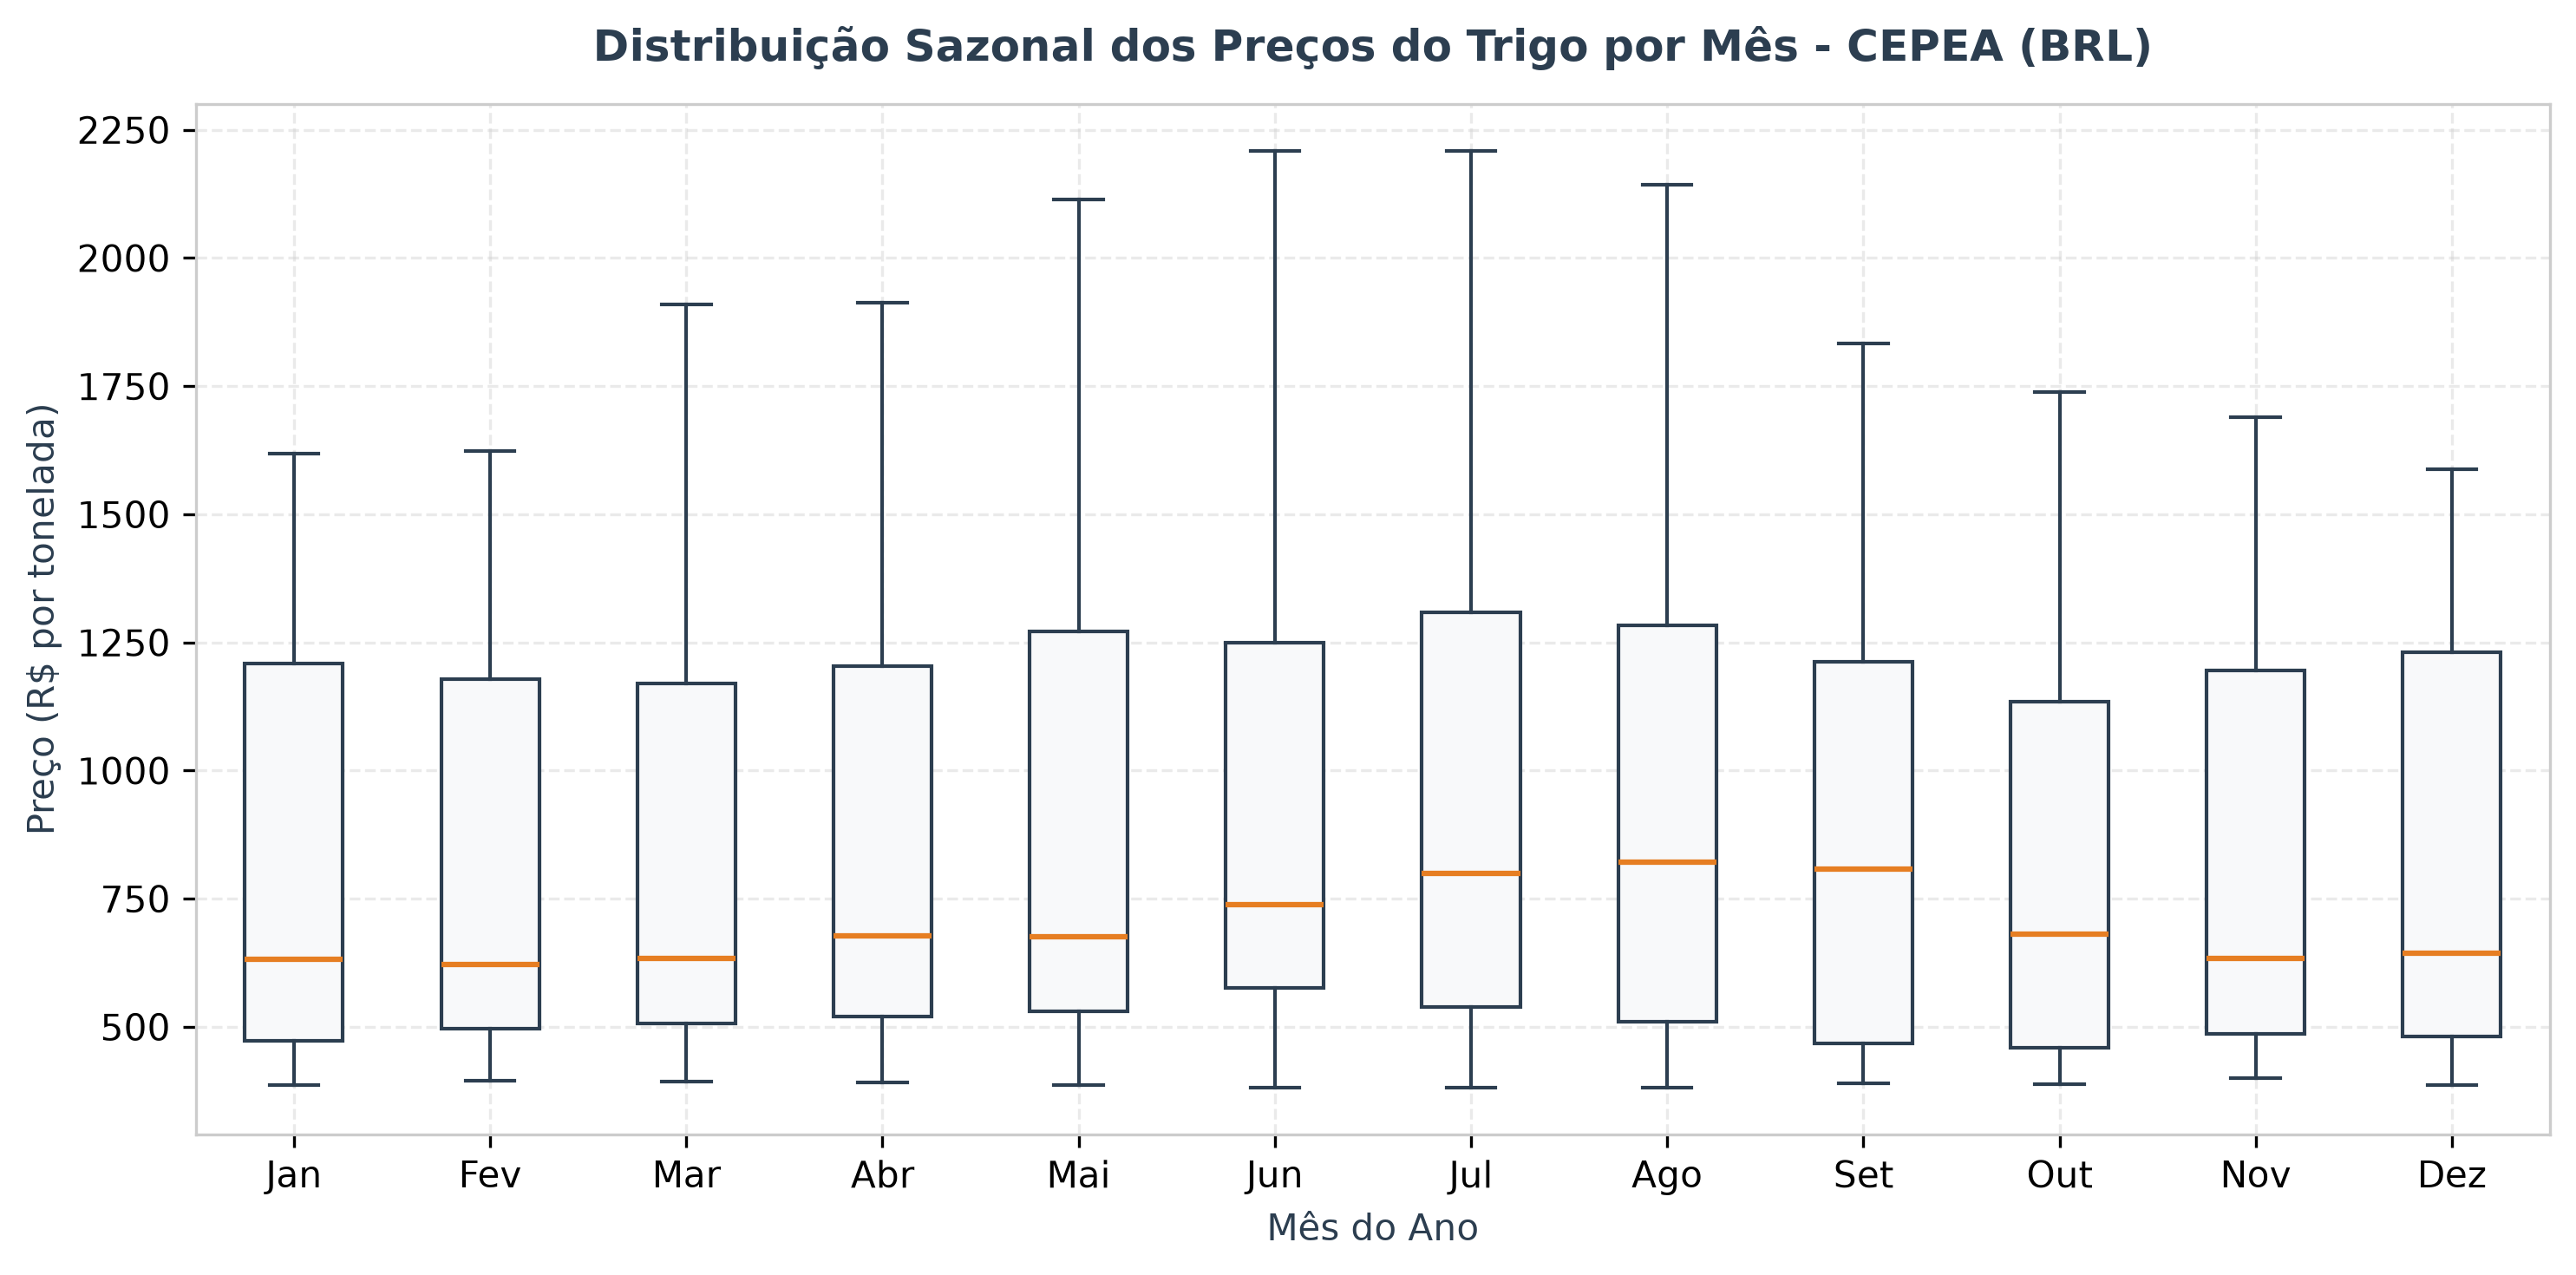

In [13]:
# 1. Agrupando os preços por mês do ano
dados_por_mes = [serie[serie.index.month == m] for m in range(1, 13)]

# 2. Criando o Gráfico de Sazonalidade (Boxplot)
fig, ax = plt.subplots(figsize=(10, 5))

bp = ax.boxplot(
    dados_por_mes,
    patch_artist=True,
    boxprops=dict(facecolor=LIGHT, color=ACCENT, linewidth=1),
    medianprops=dict(color=ACCENT_SEC, linewidth=1.5),
    whiskerprops=dict(color=ACCENT, linewidth=1),
    capprops=dict(color=ACCENT, linewidth=1),
)

# Estilização do gráfico
ax.set_title('Distribuição Sazonal dos Preços do Trigo por Mês - CEPEA (BRL)', fontsize=12, pad=12, color=ACCENT, weight='bold')
ax.set_xlabel('Mês do Ano', fontsize=10, color=ACCENT)
ax.set_ylabel('Preço (R$ por tonelada)', fontsize=10, color=ACCENT)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES_NOMES)
ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc')

plt.tight_layout()
plt.show()

O gráfico de caixas (*boxplot*) acima agrupa e resume a distribuição estatística dos preços do trigo para cada mês ao longo de toda a série histórica (2008–2026):

* **Comportamento das Medianas (Linhas Laranjas):** as medianas mensais ficam em ≈ R$ 620–635/t no primeiro trimestre, sobem gradualmente até ≈ R$ 800–820/t entre julho e setembro e recuam para ≈ R$ 635–645/t em novembro e dezembro. O desenho é o mesmo da componente sazonal: alta na entressafra e queda com a colheita gaúcha.
* **Dispersão e Amplitude:** as caixas são largas em todos os meses, pois cada mês reúne anos com patamares de preço muito diferentes (de R$ 381/t em 2010 a R$ 2.209/t em 2022). Essa dispersão dificulta a percepção visual da sazonalidade nos preços brutos — por isso a decomposição, que remove a tendência antes de medir o ciclo, é a ferramenta mais adequada.
* **Ausência de *Outliers* Extremos:** a assimetria positiva aparece nas hastes superiores longas, mas os valores altos não se concentram em um único mês, reforçando que os grandes choques (como o de 2022) têm origem macroeconômica e geopolítica, e não sazonal.

**Implicação para o TCC:** o boxplot confirma a direção do padrão sazonal, mas também mostra que ele é dominado, em magnitude, pela variação entre anos. Os modelos devem, portanto, combinar a sazonalidade anual com variáveis de nível (câmbio, inflação e defasagens do próprio preço).

### Perfil Sazonal Relativo ao Patamar de Cada Ano
Para isolar o comportamento cíclico médio sem a interferência das mudanças de patamar entre os anos, calcula-se um **índice sazonal relativo**: cada preço diário é dividido pela média do respectivo ano, e em seguida calcula-se a média desse índice por mês (acompanhada de uma faixa de ±1 desvio padrão). Um valor de 1,05, por exemplo, indica que o preço daquele mês fica, em média, 5% acima da média anual.

**Justificativa Técnica:**
No notebook do arroz o perfil sazonal foi calculado sobre os preços brutos, o que fez a banda de desvio padrão refletir a mudança de patamar entre os anos. A normalização pela média anual corrige esse efeito e torna o perfil diretamente comparável entre períodos de preços baixos e altos.

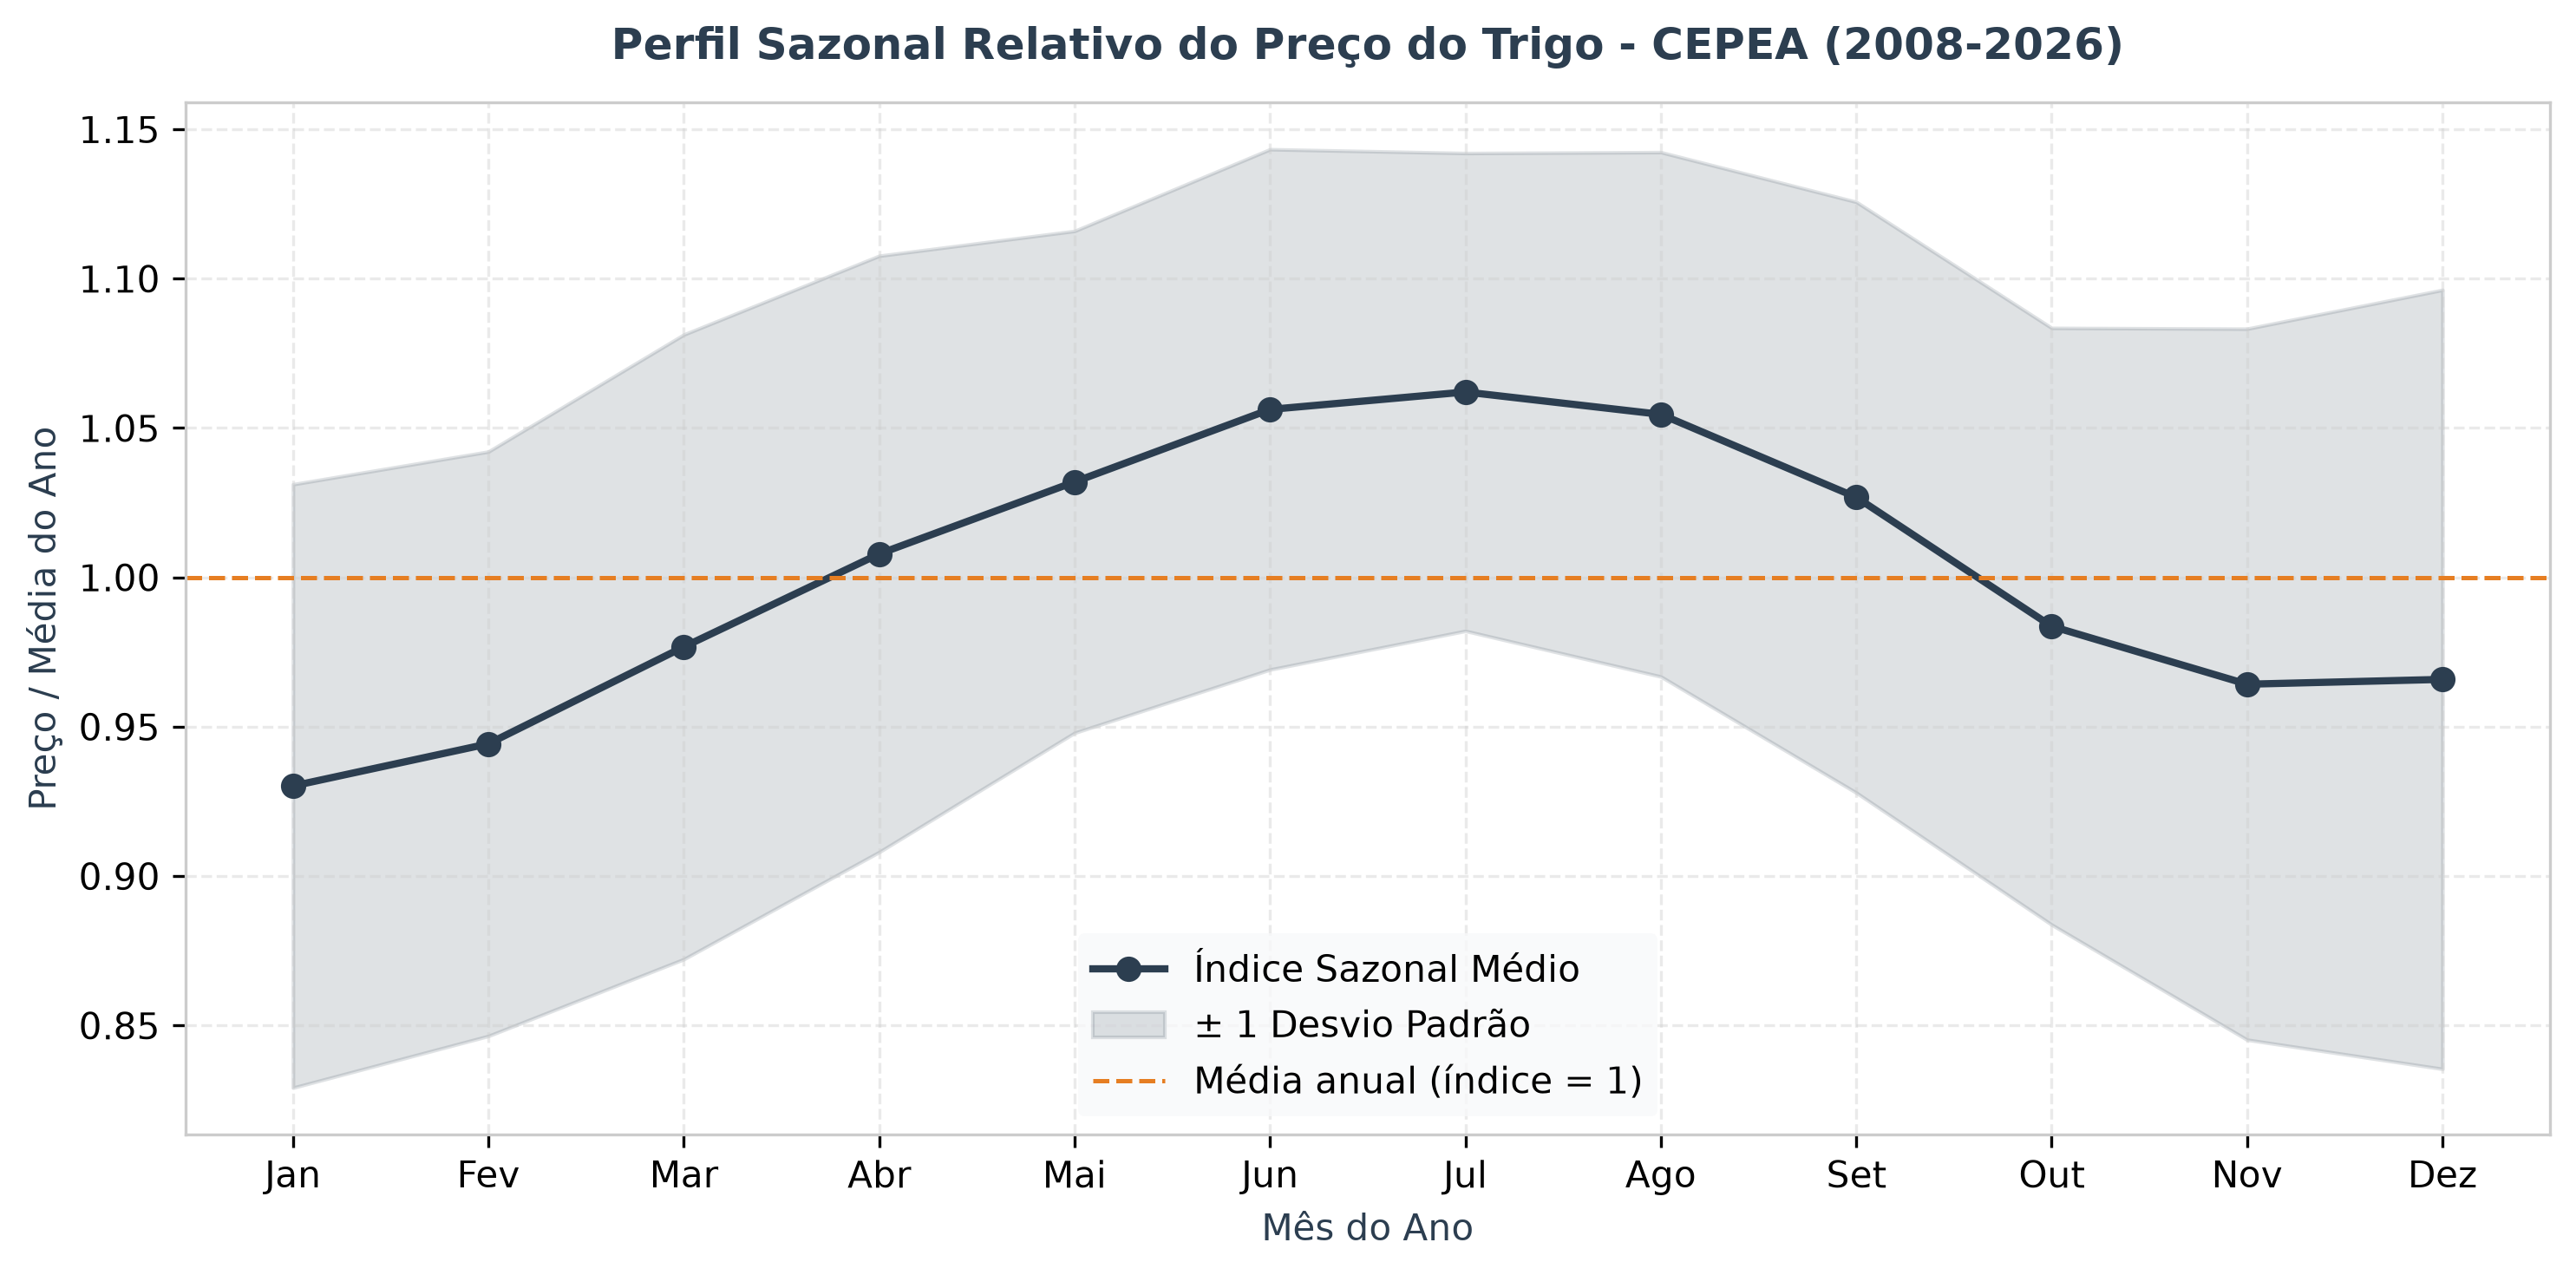

,Desvio médio em relação à média anual (%)
Mês,
Jan,-7.0
Fev,-5.6
Mar,-2.3
Abr,0.8
Mai,3.2
Jun,5.6
Jul,6.2
Ago,5.5
Set,2.7


In [14]:
# 1. Índice sazonal relativo: preço diário / média do respectivo ano
indice_relativo = serie / serie.groupby(serie.index.year).transform('mean')

# 2. Média e desvio padrão do índice por mês
perfil = indice_relativo.groupby(indice_relativo.index.month).agg(['mean', 'std'])

# 3. Criando o gráfico de linha com banda de desvio padrão
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(perfil.index, perfil['mean'], color=ACCENT, linewidth=2.0, marker='o', label='Índice Sazonal Médio')
ax.fill_between(
    perfil.index,
    perfil['mean'] - perfil['std'],
    perfil['mean'] + perfil['std'],
    color=ACCENT, alpha=0.15, label='± 1 Desvio Padrão'
)
ax.axhline(1, color=ACCENT_SEC, linestyle='--', linewidth=1.2, label='Média anual (índice = 1)')

ax.set_title('Perfil Sazonal Relativo do Preço do Trigo - CEPEA (2008-2026)', fontsize=12, pad=12, color=ACCENT, weight='bold')
ax.set_xlabel('Mês do Ano', fontsize=10, color=ACCENT)
ax.set_ylabel('Preço / Média do Ano', fontsize=10, color=ACCENT)
ax.set_xticks(perfil.index)
ax.set_xticklabels(MESES_NOMES)
ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.legend(frameon=True, facecolor=LIGHT, edgecolor='none')

plt.tight_layout()
plt.show()

display(((perfil['mean'] - 1) * 100).round(1).rename('Desvio médio em relação à média anual (%)').to_frame().set_index(pd.Index(MESES_NOMES, name='Mês')))

O perfil sazonal relativo confirma, agora em termos percentuais e livre do efeito de patamar, o ciclo identificado pela decomposição:

* **Pico na Entressafra:** os preços ficam, em média, **≈ 6,2% acima da média anual em julho** (≈ 5,6% em junho e ≈ 5,5% em agosto), e permanecem acima dela de abril a setembro.
* **Vale na Colheita e no Início do Ano:** de outubro a março os preços ficam abaixo da média anual, com os menores índices em **janeiro (≈ −7,0%)** e **fevereiro (≈ −5,6%)**, logo após a colheita gaúcha.
* **Banda de Variação:** a faixa de ±1 desvio padrão é mais estreita no meio do ano e mais larga em novembro e dezembro — natural, pois os meses do fim do ano são os mais distantes da média anual em anos de forte tendência (alta ou baixa) e, portanto, mais sensíveis a ela.

**Implicação para o TCC:** um ciclo médio de ≈ 13 pontos percentuais entre o pico (julho) e o vale (janeiro) é relevante para previsão de curto e médio prazo, sobretudo para horizontes que atravessam a transição entre entressafra e colheita.

### Análise de Subséries Sazonais
O gráfico de subséries sazonais desagrega a série temporal em doze painéis mensais, permitindo examinar simultaneamente a evolução interanual de cada mês e o seu patamar médio de referência (destacado pela linha horizontal), no mesmo formato utilizado para o arroz.

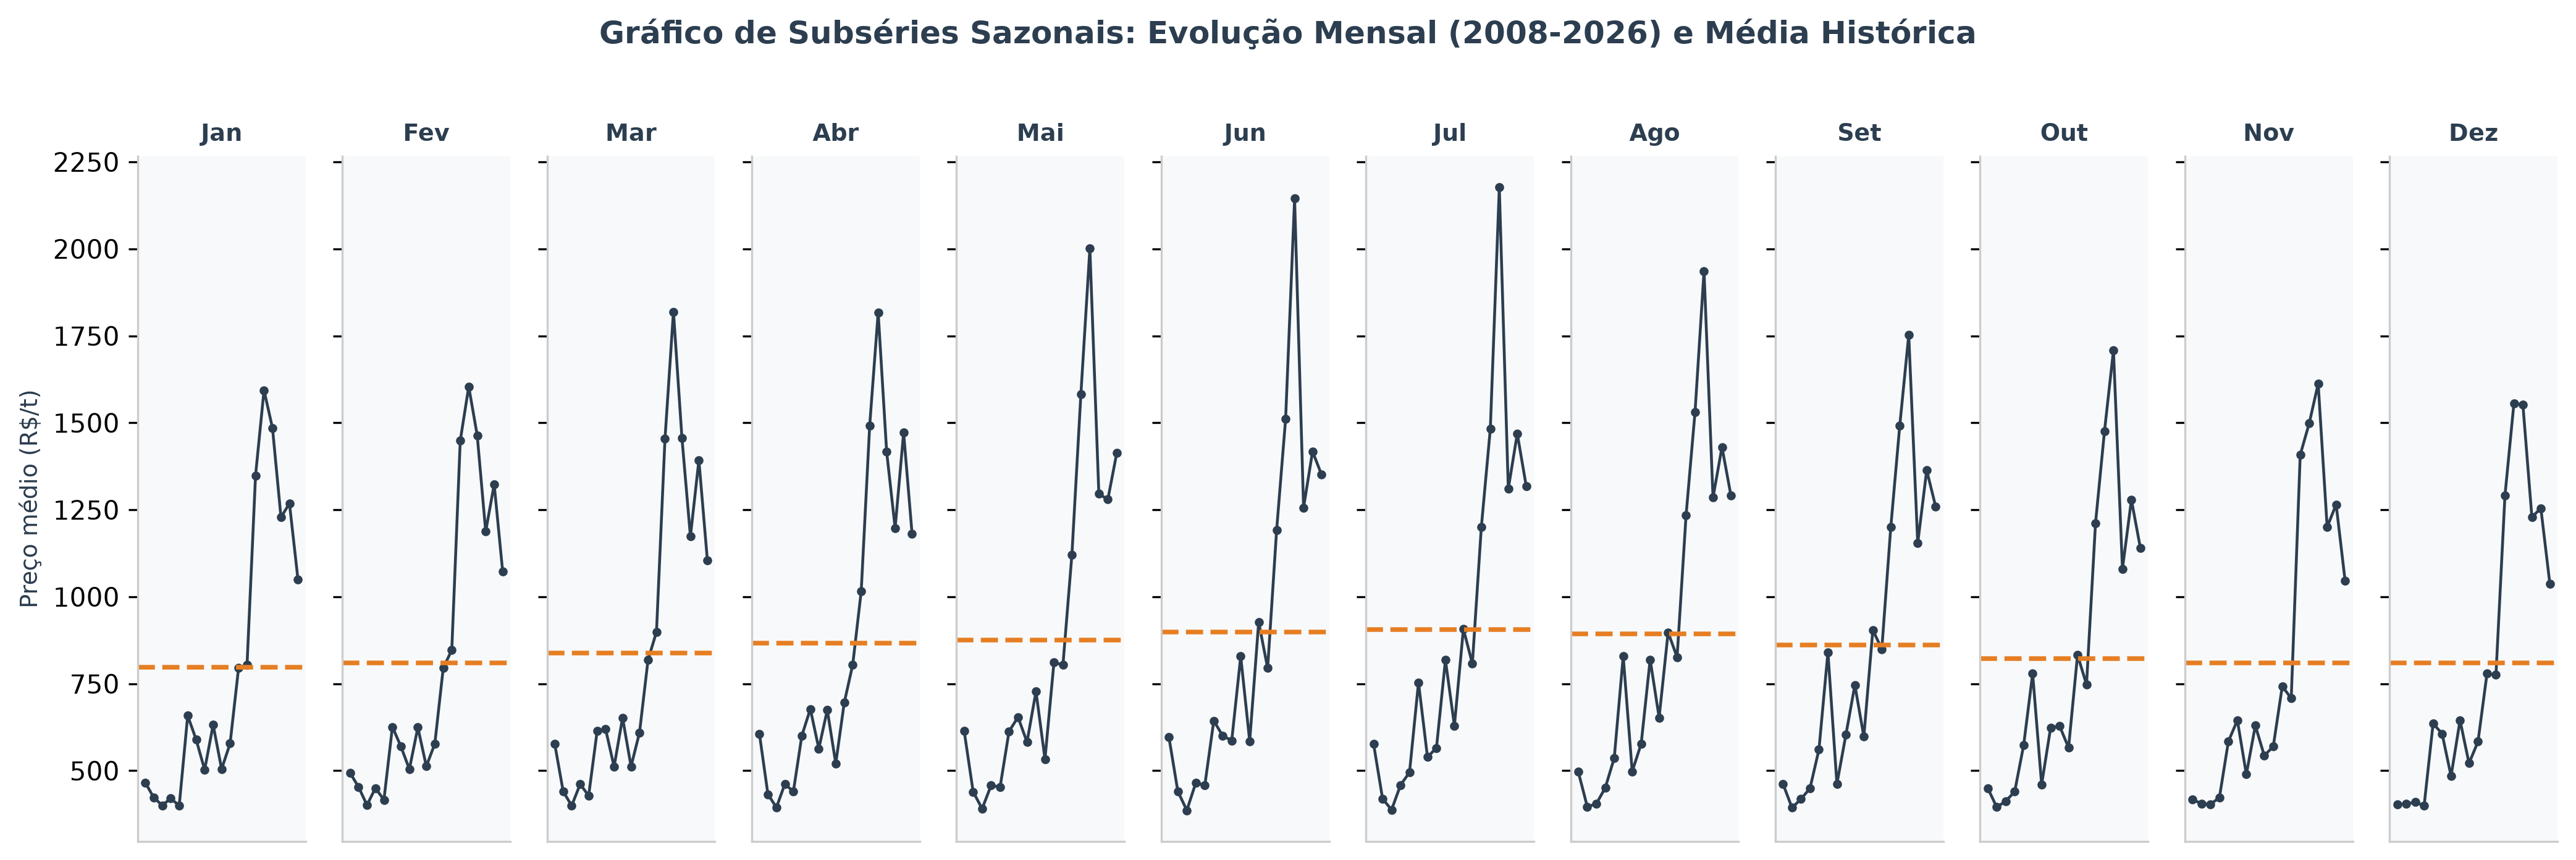

In [15]:
# 1. Preço médio de cada mês em cada ano (uma observação por mês/ano)
mensal = serie.groupby([serie.index.year.rename('ano'), serie.index.month.rename('mes')]).mean().reset_index()

# 2. Média histórica de cada mês
medias_mensais = mensal.groupby('mes')['preco_brl'].mean()

# 3. Criando a figura com 12 painéis (um para cada mês) compartilhando o eixo Y
fig, axes = plt.subplots(1, 12, figsize=(14, 4.5), sharey=True)

for m in range(1, 13):
    ax = axes[m - 1]
    ax.set_facecolor(LIGHT)

    # Evolução do mês ao longo dos anos
    dados_mes = mensal[mensal['mes'] == m]
    ax.plot(dados_mes['ano'], dados_mes['preco_brl'], marker='o', markersize=2.5, linewidth=1.1, color=ACCENT)

    # Linha horizontal indicando a média histórica daquele mês específico
    ax.axhline(medias_mensais[m], color=ACCENT_SEC, linewidth=1.8, linestyle='--')

    ax.set_title(MESES_NOMES[m - 1], fontsize=9, color=ACCENT, weight='bold')
    ax.set_xticks([])  # Remove os ticks do eixo X

    # Removendo bordas desnecessárias
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

axes[0].set_ylabel('Preço médio (R$/t)', fontsize=9, color=ACCENT)
fig.suptitle('Gráfico de Subséries Sazonais: Evolução Mensal (2008-2026) e Média Histórica', fontsize=12, color=ACCENT, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

* **Comportamento Intra-mês:** cada painel mostra a trajetória de um mês específico entre 2008 e 2026. A tendência de longo prazo — patamar baixo até 2012, alta gradual até 2019, salto em 2020–2022 e correção a partir de 2023 — repete-se em todos os meses do ano, evidenciando que o principal motor da série é comum a todos os períodos.
* **Diferença entre as Médias:** as linhas de referência dos meses de junho a setembro ficam visivelmente acima das de novembro a março, reproduzindo o ciclo de entressafra e colheita do trigo gaúcho.
* **Consolidação do Padrão Temporal:** o mercado de trigo combina uma **tendência macroeconômica dominante** com um **ciclo sazonal anual consistente**, o que o diferencia do arroz, cuja sazonalidade mensal se mostrou pouco relevante.

## 5. Análise de Autocorrelação (ACF e PACF)

### Fundamentação Teórica
* A **Função de Autocorrelação (ACF)** mede a correlação entre a série e suas próprias defasagens, $\rho_k = \text{Corr}(Y_t, Y_{t-k})$, incluindo efeitos indiretos transmitidos pelas defasagens intermediárias.
* A **Função de Autocorrelação Parcial (PACF)** mede a correlação entre $Y_t$ e $Y_{t-k}$ **removendo** o efeito das defasagens intermediárias $1, \dots, k-1$.

A leitura conjunta dos dois gráficos orienta a escolha preliminar das ordens do modelo (metodologia de Box-Jenkins):

| Padrão observado | Modelo sugerido |
|---|---|
| ACF decai gradualmente e PACF é **cortada** após a defasagem $p$ | AR($p$) |
| ACF é **cortada** após a defasagem $q$ e PACF decai gradualmente | MA($q$) |
| ACF e PACF decaem gradualmente | ARMA($p$, $q$) |
| Picos nas defasagens múltiplas de $s$ (7, 14, 21, ...) | Componente sazonal com período $s$ |

As faixas sombreadas representam o intervalo de confiança de 95%; barras fora delas são estatisticamente diferentes de zero. Como a série em nível é $I(1)$ (Seção 3), a análise é feita sobre a **primeira diferença** ($\Delta Y_t$), que é estacionária.

### ACF e PACF da Série em Primeira Diferença
**Justificativa Técnica:**
Utilizam-se `plot_acf` e `plot_pacf` do `statsmodels` com 40 defasagens (pouco menos de seis semanas), suficiente para observar a dinâmica de curto prazo e as possíveis repetições semanais (múltiplos de 7). Para comparação, também se apresenta a ACF da série em nível, que ilustra o padrão típico de uma série não estacionária.

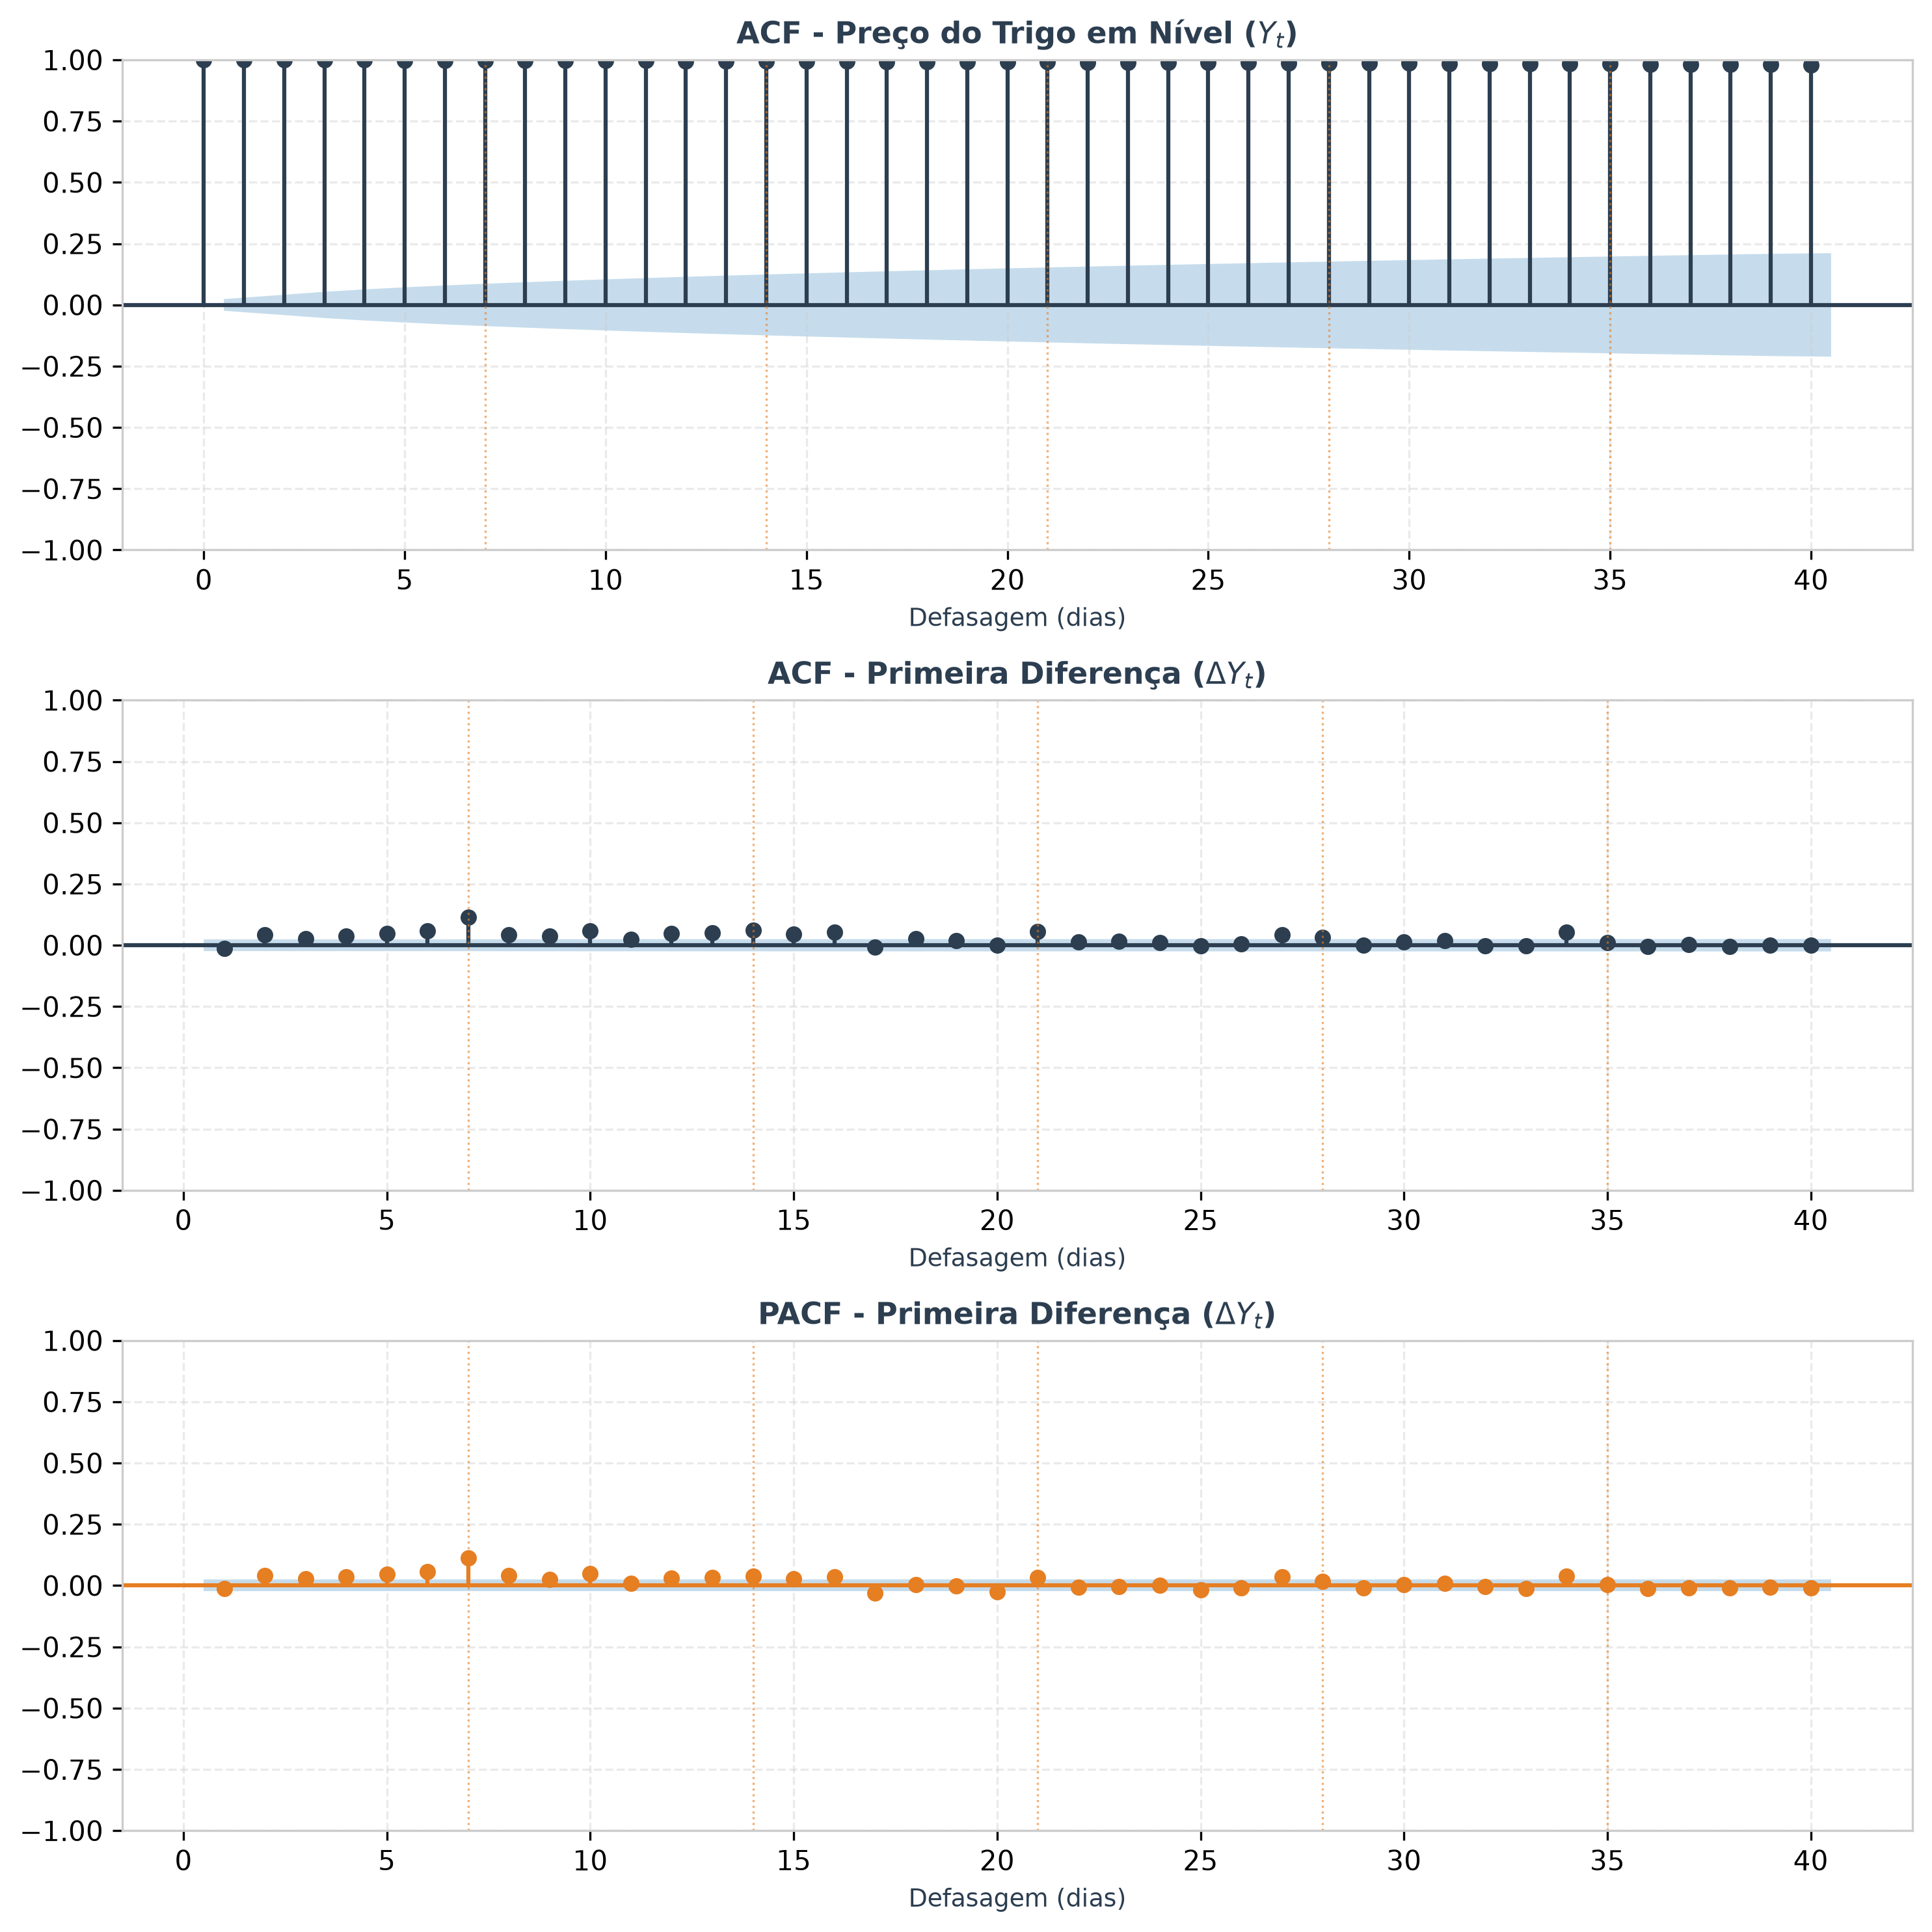

Limite aproximado de significância (95%): ±0.0240
ACF da 1ª diferença nas defasagens 1-3 e nos múltiplos de 7:
  lag  1: -0.012
  lag  2: +0.041
  lag  3: +0.027
  lag  7: +0.115
  lag 14: +0.060
  lag 21: +0.056
  lag 28: +0.032
  lag 35: +0.010


In [16]:
N_LAGS = 40

fig, axes = plt.subplots(3, 1, figsize=(10, 10))

# ACF da série em nível (referência: série não estacionária)
plot_acf(serie, lags=N_LAGS, ax=axes[0], color=ACCENT, vlines_kwargs={'colors': ACCENT})
axes[0].set_title('ACF - Preço do Trigo em Nível ($Y_t$)', fontsize=11, color=ACCENT, weight='bold')

# ACF e PACF da série em primeira diferença
plot_acf(serie_diff, lags=N_LAGS, ax=axes[1], zero=False, color=ACCENT, vlines_kwargs={'colors': ACCENT})
axes[1].set_title(r'ACF - Primeira Diferença ($\Delta Y_t$)', fontsize=11, color=ACCENT, weight='bold')

plot_pacf(serie_diff, lags=N_LAGS, ax=axes[2], zero=False, method='ywm', color=ACCENT_SEC, vlines_kwargs={'colors': ACCENT_SEC})
axes[2].set_title(r'PACF - Primeira Diferença ($\Delta Y_t$)', fontsize=11, color=ACCENT, weight='bold')

for ax in axes:
    ax.set_xlabel('Defasagem (dias)', fontsize=9, color=ACCENT)
    ax.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
    # Marcação das defasagens semanais (múltiplos de 7)
    for k in range(7, N_LAGS + 1, 7):
        ax.axvline(k, color=ACCENT_SEC, linestyle=':', linewidth=0.8, alpha=0.6)

plt.tight_layout()
plt.show()

# Valores numéricos das primeiras defasagens e das defasagens semanais
acf_vals = acf(serie_diff, nlags=N_LAGS)
limite = 1.96 / np.sqrt(len(serie_diff))
print(f"Limite aproximado de significância (95%): ±{limite:.4f}")
print("ACF da 1ª diferença nas defasagens 1-3 e nos múltiplos de 7:")
for k in [1, 2, 3, 7, 14, 21, 28, 35]:
    print(f"  lag {k:>2}: {acf_vals[k]:+.3f}")

**Orientações para a leitura dos gráficos:**

* **ACF em Nível:** as autocorrelações começam próximas de 1 e decaem de forma extremamente lenta, padrão clássico de uma série com raiz unitária. Esse gráfico, sozinho, já justificaria a diferenciação.
* **ACF da Primeira Diferença:** após a diferenciação, as autocorrelações caem para valores **pequenos em magnitude** (todas abaixo de 0,12). A defasagem 1 é praticamente nula (≈ −0,01, não significativa). O destaque é um **pico isolado na defasagem 7 (≈ 0,115)**, seguido de picos menores nos múltiplos de 7 (≈ 0,06 nos lags 14 e 21), em meio a autocorrelações positivas e fracas (≈ 0,03 a 0,06) até a defasagem ≈ 16.
* **PACF da Primeira Diferença:** reproduz o mesmo desenho — um pico claro na defasagem 7 (≈ 0,11) e valores pequenos nas demais, que se aproximam de zero após a defasagem ≈ 16, sem um corte abrupto nas primeiras defasagens.

**Interpretação Econômica:**

* **Ausência de inércia nas variações de um dia para o outro:** com autocorrelação praticamente nula no lag 1, a variação de hoje quase não ajuda a prever a de amanhã — comportamento próximo de um passeio aleatório, típico de preços de mercado.
* **Leve persistência de médio prazo:** as autocorrelações positivas e fracas nas primeiras semanas indicam uma transmissão gradual de choques do câmbio e das cotações internacionais para o mercado físico gaúcho.
* **Periodicidade semanal:** o pico dominante no lag 7 reflete o calendário de negociação — os finais de semana preenchidos por *forward fill* geram variações nulas que se repetem a cada 7 dias, e as cotações tendem a se ajustar em dias específicos da semana. Essa estrutura justifica uma componente sazonal semanal ($s = 7$).
* **Significância estatística versus prática:** com mais de 6.600 observações, o intervalo de confiança é muito estreito (≈ ±0,024), de modo que correlações pequenas já aparecem como "significativas". Na prática, nenhuma defasagem isolada explica muito da variação diária, o que indica que **modelos parcimoniosos** são preferíveis.

**Identificação Preliminar dos Parâmetros (SARIMA):**

| Parâmetro | Valor sugerido | Evidência |
|---|---|---|
| $d$ (diferenciação) | **1** | Testes ADF e KPSS (Seção 3) |
| $p$ (autorregressivo) | **0 a 1** | PACF sem pico relevante nas primeiras defasagens |
| $q$ (médias móveis) | **0 a 1** | ACF sem pico relevante nas primeiras defasagens |
| $s$ (período sazonal) | **7** | Pico dominante no lag 7 da ACF e da PACF |
| $P$, $D$, $Q$ (sazonais) | **(1, 0, 1)** | Pico sazonal moderado e decrescente nos múltiplos de 7, sem necessidade de diferença sazonal |

Como ponto de partida, recomenda-se adotar a **mesma especificação do arroz, SARIMA(1, 1, 1)(1, 0, 1, 7)**, o que garante a comparabilidade metodológica entre as commodities. Como a parte não sazonal é fraca, vale testar também especificações mais simples, como SARIMA(0, 1, 1)(1, 0, 1, 7) e SARIMA(1, 1, 0)(1, 0, 1, 7). A especificação deve então ser refinada comparando modelos candidatos pelos critérios de informação (AIC/BIC) e validada pelo diagnóstico dos resíduos (teste de Ljung-Box), que devem se comportar como ruído branco. A dependência fraca porém persistente ao longo de várias semanas também reforça o uso de janelas de entrada de várias semanas na LSTM.

### Análise de Defasagem (Lag Plot)
Complementando a ACF, o diagrama de dispersão de defasagem compara visualmente o preço em $t$ com o preço em $t-k$, no mesmo formato utilizado para o arroz.

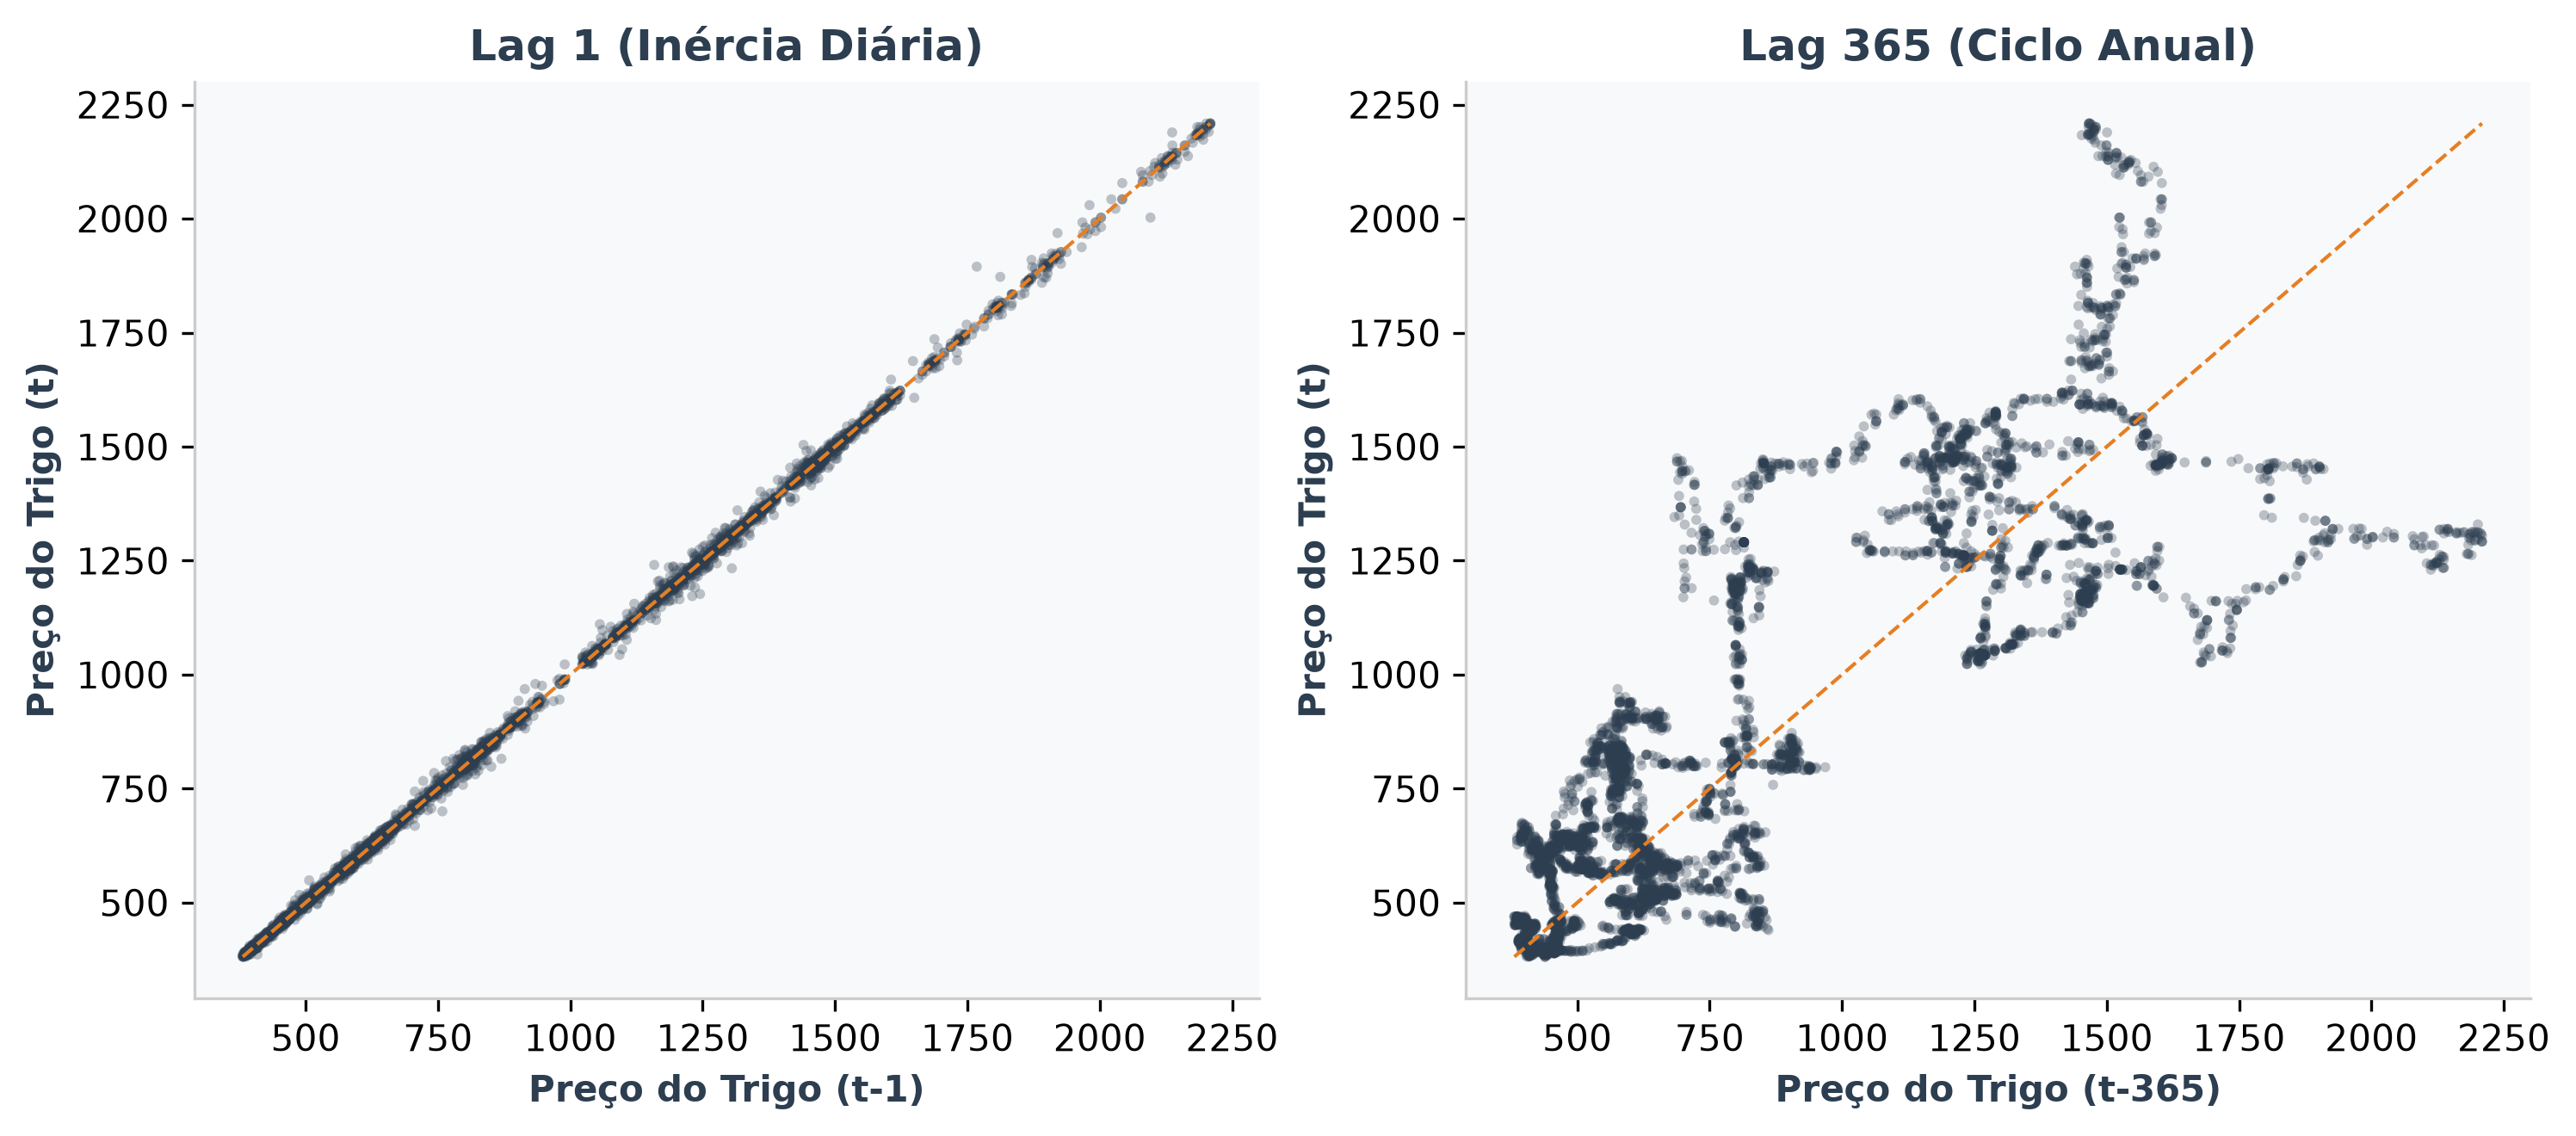

In [17]:
lags = [1, 365]
titulos = ["Lag 1 (Inércia Diária)", "Lag 365 (Ciclo Anual)"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, lag, titulo in zip(axes, lags, titulos):
    ax.set_facecolor(LIGHT)

    # Pontos pequenos e transparentes para evitar o efeito de "bloco pesado"
    ax.scatter(serie.shift(lag), serie, s=8, alpha=0.3, color=ACCENT, edgecolor='none')

    # Diagonal de referência (preço em t igual ao preço em t-lag)
    limites = [serie.min(), serie.max()]
    ax.plot(limites, limites, color=ACCENT_SEC, linestyle='--', linewidth=1)

    ax.set_xlabel(f"Preço do Trigo (t-{lag})", fontsize=10, color=ACCENT, weight='bold')
    ax.set_ylabel("Preço do Trigo (t)", fontsize=10, color=ACCENT, weight='bold')
    ax.set_title(titulo, fontsize=12, color=ACCENT, weight='bold')

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

* **Lag 1 (Inércia Diária):** os pontos se alinham de forma praticamente perfeita sobre a diagonal, revelando uma inércia de curto prazo altíssima: o preço do trigo em um dia ($t$) é determinado quase integralmente pelo preço do dia anterior ($t-1$). Esse é o retrato visual de um processo com raiz unitária, coerente com o resultado $I(1)$.
* **Lag 365 (Ciclo Anual):** a dispersão é muito maior e forma trajetórias em laço, com pontos bem acima da diagonal (anos de alta, como 2020–2022) e bem abaixo dela (anos de correção, como 2023). Isso mostra que, embora exista um ciclo sazonal anual, o preço de um ano não é um bom preditor do preço do ano seguinte, porque as mudanças de patamar dominam.

**Implicações para a Modelagem LSTM:** a combinação de uma dependência de curtíssimo prazo muito forte (Lag 1) com uma relação anual instável e não-linear (Lag 365) indica que o preço defasado é o preditor isolado mais importante, mas que a qualidade da previsão em horizontes maiores depende de variáveis explicativas adicionais e de modelos capazes de capturar relações não-lineares.

## 6. Conclusões e Implicações para a Modelagem

A Análise Exploratória de Dados da série diária de preços do trigo (CEPEA/ESALQ - Rio Grande do Sul, 2008–2026) permite sintetizar os seguintes achados:

| Dimensão | Principal achado | Implicação para a modelagem |
|---|---|---|
| **Integridade** | Série diária contínua, sem valores nulos; ≈ 35% dos dias sem variação (fins de semana e feriados via *forward fill*) | Dados aptos para SARIMA e LSTM; *forward fill* gera padrão semanal |
| **Nível e Tendência** | Preço de R$ 381/t (2010) a R$ 2.209/t (2022), com mudanças de patamar | Variáveis macroeconômicas (câmbio, inflação) são essenciais |
| **Distribuição** | Assimetria positiva, distribuição multimodal (regimes de preço) e CV ≈ 50% | Normalização obrigatória para a LSTM; atenção às quebras estruturais |
| **Volatilidade** | Volatilidade variável no tempo, com picos em 2013, 2024 e 2016 | Heterocedasticidade; intervalos de confiança lineares tendem a ser estreitos nas crises |
| **Estacionariedade** | Nível não estacionário; 1ª diferença estacionária (ADF e KPSS concordantes) | Série $I(1)$: **$d = 1$** no SARIMA/SARIMAX |
| **Sazonalidade** | Ciclo anual nítido: pico em julho (entressafra) e vale em dezembro/janeiro (após a colheita gaúcha), amplitude ≈ R$ 115/t (≈ 13%) | Variáveis sazonais cíclicas (seno/cosseno) e clima da safra de inverno são relevantes |
| **Autocorrelação** | Lag 1 praticamente nulo; pico dominante no lag 7 e dependência fraca nas primeiras semanas | Ponto de partida: **SARIMA(1, 1, 1)(1, 0, 1, 7)**, comparado com variantes mais simples por AIC/BIC e Ljung-Box |

**Comparação com o Arroz:** as duas commodities gaúchas compartilham a não-estacionariedade em nível ($I(1)$), a forte inércia diária dos preços e o choque de preços pós-2020. A principal diferença é a **sazonalidade**: enquanto o arroz não apresentou um ciclo mensal relevante, o trigo exibe um ciclo anual consistente e diretamente associado ao calendário da safra de inverno no Rio Grande do Sul.

**Encaminhamento para a Fase de Modelagem:**

* **SARIMA (baseline univariado):** especificação inicial idêntica à do arroz, $d = 1$ e sazonalidade semanal ($s = 7$), com comparação de candidatos por AIC/BIC e validação dos resíduos.
* **SARIMAX:** inclusão de variáveis exógenas — em especial o **câmbio (dólar)**, dado o papel das importações na formação do preço doméstico do trigo, e as variáveis climáticas da safra de inverno.
* **LSTM:** uso do dataset integrado `dataset_final_trigo.csv` (36 variáveis explicativas, com mesmas colunas do dataset do arroz), com normalização dos dados e janelas de entrada de várias semanas, para capturar a combinação de inércia de curto prazo, sazonalidade anual e choques não-lineares identificada nesta análise.